| Name | VILLALINO, Paul Benedict O. |
|---|---|
| ID Number | 2025300951 |
| Section | CEA_CPE_2D_NONSTEM |

# Coding Assignment 3: Backpropagation and Optimization

---
# 1. Environment Setup and Data Exploration

## 1.1 Package Imports


In [1]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')   # hide TensorFlow's start-up chatter
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
import keras
from keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Times New Roman'
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'Liberation Serif', 'DejaVu Serif']

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
keras.utils.set_random_seed(SEED)    # seeds Python, NumPy and TensorFlow at once

print('Keras version :', keras.__version__)
print('TensorFlow version :', tf.__version__)
print('NumPy / pandas :', np.__version__, '/', pd.__version__)
print('Physical GPUs visible :', len(tf.config.list_physical_devices('GPU')))

Keras version : 3.16.0.dev2026110203
TensorFlow version : 2.22.0-rc0
NumPy / pandas : 2.5.1 / 3.0.5
Physical GPUs visible : 0


## 1.2 Load the Dataset


In [2]:
CSV_CANDIDATES = ['Family Income and Expenditure.csv',
                  'Family_Income_and_Expenditure.csv']
CSV_PATH = next((p for p in CSV_CANDIDATES if os.path.exists(p)), None)
if CSV_PATH is None:
    raise FileNotFoundError('Put the FIES csv next to this notebook. Tried: ' + ', '.join(CSV_CANDIDATES))

df = pd.read_csv(CSV_PATH)
print('Loaded :', CSV_PATH)
print('Shape  :', df.shape)
df.head()

Loaded : Family Income and Expenditure.csv
Shape  : (41544, 60)


,Total Household Income,Region,Total Food Expenditure,Main Source of Income,Agricultural Household indicator,Bread and Cereals Expenditure,Total Rice Expenditure,Meat Expenditure,Total Fish and marine products Expenditure,Fruit Expenditure,...,Number of Refrigerator/Freezer,Number of Washing Machine,Number of Airconditioner,"Number of Car, Jeep, Van",Number of Landline/wireless telephones,Number of Cellular phone,Number of Personal Computer,Number of Stove with Oven/Gas Range,Number of Motorized Banca,Number of Motorcycle/Tricycle
0,480332,CAR,117848,Wage/Salaries,0,42140,38300,24676,16806,3325,...,1,1,0,0,0,2,1,0,0,1
1,198235,CAR,67766,Wage/Salaries,0,17329,13008,17434,11073,2035,...,0,1,0,0,0,3,1,0,0,2
2,82785,CAR,61609,Wage/Salaries,1,34182,32001,7783,2590,1730,...,0,0,0,0,0,0,0,0,0,0
3,107589,CAR,78189,Wage/Salaries,0,34030,28659,10914,10812,690,...,0,0,0,0,0,1,0,0,0,0
4,189322,CAR,94625,Wage/Salaries,0,34820,30167,18391,11309,1395,...,1,0,0,0,0,3,0,0,0,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41544 entries, 0 to 41543
Data columns (total 60 columns):
 #   Column                                         Non-Null Count  Dtype
---  ------                                         --------------  -----
 0   Total Household Income                         41544 non-null  int64
 1   Region                                         41544 non-null  str  
 2   Total Food Expenditure                         41544 non-null  int64
 3   Main Source of Income                          41544 non-null  str  
 4   Agricultural Household indicator               41544 non-null  int64
 5   Bread and Cereals Expenditure                  41544 non-null  int64
 6   Total Rice Expenditure                         41544 non-null  int64
 7   Meat Expenditure                               41544 non-null  int64
 8   Total Fish and  marine products Expenditure    41544 non-null  int64
 9   Fruit Expenditure                              41544 non-null  int64
 10  Vegetable

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Total Household Income,41544.0,247555.584802,286880.522653,11285.0,104895.00,164079.5,291138.50,11815988.0
Total Food Expenditure,41544.0,85099.158194,51637.947682,2947.0,51017.25,72985.5,105635.50,827565.0
Agricultural Household indicator,41544.0,0.429858,0.676666,0.0,0.00,0.0,1.00,2.0
Bread and Cereals Expenditure,41544.0,25133.723642,13466.482984,0.0,16556.00,23324.0,31439.00,765864.0
Total Rice Expenditure,41544.0,18195.825005,11727.224350,0.0,11020.00,16620.0,23920.00,758326.0
Meat Expenditure,41544.0,10540.072574,10497.727757,0.0,3353.75,7332.5,14292.00,261566.0
Total Fish and marine products Expenditure,41544.0,10529.318337,7812.201613,0.0,5504.00,8695.0,13388.00,188208.0
Fruit Expenditure,41544.0,2550.474990,2969.752879,0.0,1024.75,1820.0,3100.00,273769.0
Vegetables Expenditure,41544.0,5006.918568,3300.175236,0.0,2873.00,4314.0,6304.25,74800.0
Restaurant and hotels Expenditure,41544.0,15436.566075,23705.195929,0.0,1930.00,7314.0,19921.25,725296.0


In [5]:
missing = df.isna().sum()
print('Columns with missing values:')
print(missing[missing > 0].to_string())
numeric_missing = df.select_dtypes(include=np.number).isna().sum().sum()
print('\nMissing values inside NUMERIC columns:', numeric_missing)

Columns with missing values:
Household Head Occupation         7536
Household Head Class of Worker    7536
Toilet Facilities                 1580

Missing values inside NUMERIC columns: 0


In [6]:
TARGET = 'Total Food Expenditure'
assert TARGET in df.columns, f'Target column {TARGET!r} not found'

print("Exact column 'Total Income' present?  ->", 'Total Income' in df.columns)
income_like = [c for c in df.columns if 'income' in c.lower()]
print('Columns whose name contains "income":')
for c in income_like:
    print('   -', repr(c))

INCOME_COL = 'Total Household Income'
assert INCOME_COL in df.columns, 'Expected the household income column was not found'
print(f'\n-> The assignment\'s "Total Income" corresponds to {INCOME_COL!r} in this csv.')
print('   Note: "Total Income from Entrepreneurial Acitivites" is a DIFFERENT column (one income')
print('   source, with the dataset\'s own spelling). The sheet only asks to exclude the total, so it stays a feature.')

Exact column 'Total Income' present?  -> False
Columns whose name contains "income":
   - 'Total Household Income'
   - 'Main Source of Income'
   - 'Total Income from Entrepreneurial Acitivites'

-> The assignment's "Total Income" corresponds to 'Total Household Income' in this csv.
   Note: "Total Income from Entrepreneurial Acitivites" is a DIFFERENT column (one income
   source, with the dataset's own spelling). The sheet only asks to exclude the total, so it stays a feature.


## Reflection Question 1
What does each row in the FIES dataset represent? Identify at least two demographic columns and two expenditure columns visible in `df.head()`.

### Answer
Each row is **one household**, not one person. The income and spending numbers are yearly totals for the whole family.

- **Demographic columns** in `df.head()`: `Region` and `Main Source of Income` (also `Agricultural Household indicator`). Further right in the full table there are also `Household Head Sex` and `Household Head Age`.

- **Expenditure columns** in `df.head()`: `Total Food Expenditure` and `Bread and Cereals Expenditure` (also `Total Rice Expenditure`, `Meat Expenditure`, `Fruit Expenditure`, and more).

The data has 41,544 households and 60 columns.

## Reflection Question 2
The prediction target is Total Food Expenditure. Which column(s) should be excluded from the feature set to prevent data leakage? Justify your choice.



In [7]:
FOOD_COMPONENTS = ['Bread and Cereals Expenditure',
                   'Total Rice Expenditure',
                   'Meat Expenditure',
                   'Total Fish and  marine products Expenditure',   # the double space is in the original header
                   'Fruit Expenditure',
                   'Vegetables Expenditure']
missing_cols = [c for c in FOOD_COMPONENTS if c not in df.columns]
assert not missing_cols, missing_cols

audit = pd.DataFrame({
    'corr with target': df[FOOD_COMPONENTS + [INCOME_COL]].corrwith(df[TARGET]),
    'median share of target': df[FOOD_COMPONENTS + [INCOME_COL]].div(df[TARGET], axis=0).median(),
})
display(audit.round(3))

no_rice = [c for c in FOOD_COMPONENTS if c != 'Total Rice Expenditure']   # rice is already inside "Bread and Cereals"
share = df[no_rice].sum(axis=1) / df[TARGET]
print('Sum of the 5 food-group columns (rice left out so it is not counted twice) divided by the target:')
print(share.describe().round(3).to_string())
print('\nSo the components cover roughly two thirds of the target on average, but they are NOT an exact decomposition of it.')

,corr with target,median share of target
Bread and Cereals Expenditure,0.600,0.319
Total Rice Expenditure,0.436,0.223
Meat Expenditure,0.771,0.103
Total Fish and marine products Expenditure,0.606,0.119
Fruit Expenditure,0.526,0.025
Vegetables Expenditure,0.556,0.059
Total Household Income,0.664,2.285


Sum of the 5 food-group columns (rice left out so it is not counted twice) divided by the target:
count    41544.000
mean         0.669
std          0.145
min          0.000
25%          0.584
50%          0.693
75%          0.778
max          0.983

So the components cover roughly two thirds of the target on average, but they are NOT an exact decomposition of it.


### Answer
Two columns are left out: **Total Food Expenditure** and **Total Household Income**.

1.  **Total Food Expenditure** is the target. If it stays in the inputs, the model just copies the answer and the scores mean nothing.

2.  **Total Household Income** is left out because income and food spending go up together very closely, so the model would depend on it almost completely, and a forecast should not need the family’s income.

The food-group columns (rice, bread and cereals, meat, fish, fruit, vegetables) are parts of food spending. They stay in the baseline because the sheet sets the exclusion list to these two columns. Removing them lowers R² from 0.95 to 0.80, so they carry a large share of the prediction.

---
# 2. Data Preparation


In [8]:
EXCLUDE = [TARGET, INCOME_COL]                       # target itself + total income (leakage)

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
feature_cols = [c for c in numeric_cols if c not in EXCLUDE]

X = df[feature_cols].copy()
X = X.fillna(X.median())                              # median of each column
y = df[TARGET].copy()
y = y.fillna(y.median())

print('Numeric columns in the csv        :', len(numeric_cols))
print('Excluded                          :', EXCLUDE)
print('Number of input features          :', len(feature_cols))
print('Missing values left in X / y      :', int(X.isna().sum().sum()), '/', int(y.isna().sum()))
print('\nFeature columns:')
for i, c in enumerate(feature_cols, 1):
    print(f'{i:>3}. {c}')

Numeric columns in the csv        : 45
Excluded                          : ['Total Food Expenditure', 'Total Household Income']
Number of input features          : 43
Missing values left in X / y      : 0 / 0

Feature columns:
  1. Agricultural Household indicator
  2. Bread and Cereals Expenditure
  3. Total Rice Expenditure
  4. Meat Expenditure
  5. Total Fish and  marine products Expenditure
  6. Fruit Expenditure
  7. Vegetables Expenditure
  8. Restaurant and hotels Expenditure
  9. Alcoholic Beverages Expenditure
 10. Tobacco Expenditure
 11. Clothing, Footwear and Other Wear Expenditure
 12. Housing and water Expenditure
 13. Imputed House Rental Value
 14. Medical Care Expenditure
 15. Transportation Expenditure
 16. Communication Expenditure
 17. Education Expenditure
 18. Miscellaneous Goods and Services Expenditure
 19. Special Occasions Expenditure
 20. Crop Farming and Gardening expenses
 21. Total Income from Entrepreneurial Acitivites
 22. Household Head Age
 23. Total 

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values, test_size=0.20, random_state=SEED)

scaler_X = StandardScaler()
X_train_s = scaler_X.fit_transform(X_train)
X_test_s = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_s = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()

print('X_train_s :', X_train_s.shape)
print('X_test_s  :', X_test_s.shape)
print('y_train_s :', y_train_s.shape, '| y_test (original pesos):', y_test.shape)
print(f'\nTarget scaler -> mean = {scaler_y.mean_[0]:,.2f}, std = {scaler_y.scale_[0]:,.2f}')

X_train_s : (33235, 43)
X_test_s  : (8309, 43)
y_train_s : (33235,) | y_test (original pesos): (8309,)

Target scaler -> mean = 85,025.73, std = 51,655.18


In [10]:
chk = pd.DataFrame({
    'train mean (should be ~0)': X_train_s.mean(axis=0),
    'train std (should be ~1)': X_train_s.std(axis=0),
    'test mean (NOT exactly 0)': X_test_s.mean(axis=0),
}, index=feature_cols)
print(chk.describe().loc[['min', 'max']].round(4).to_string())

     train mean (should be ~0)  train std (should be ~1)  test mean (NOT exactly 0)
min                       -0.0                       1.0                    -0.0330
max                        0.0                       1.0                     0.0277


## 2.1 Questions
**(a)** Why is `StandardScaler` applied to the features before training a neural network?

**(b)** The scaler is `fit_transform`-ed on the training set but only `transform`-ed on the test set. Why is this distinction critical? What would go wrong if you fit the scaler on the entire dataset?

**(c)** Why is the target variable also scaled, and why must predictions be inverse-transformed before computing RMSE and R$^2$?

### Answer
**(a)** The columns are on very different sizes. Money columns are in the tens or hundreds of thousands of pesos, but counts like family size or number of rooms are small. With raw values, the big columns take over the weight updates just because of their units. `StandardScaler` gives every column mean 0 and standard deviation 1, so all inputs are on the same scale and training is faster and smoother.

**(b)** The scaler gets its mean and standard deviation from the **training rows only**, and the test rows are changed using those same numbers. The test set should act like data the model has never seen. If I fit on everything, the test rows would help set the numbers, so some test information leaks into training and the scores look better than they really are. (Notebook check: after scaling, the training columns have mean 0 but the test columns do not.)

**(c)** The target is in the tens of thousands of pesos, so the starting errors and the squared loss are huge. Scaling it keeps the loss small and training steady. Then the model predicts in *scaled* units, but `y_test` is in pesos. So I use `scaler_y.inverse_transform` on the predictions first. After that, RMSE is the typical miss **in pesos**, and R² compares predictions and real values in the same units.

---
# 3. Model Architecture


In [11]:
def build_model(input_dim, kernel_initializer='glorot_uniform'):
    """43 -> 64 (ReLU) -> 32 (ReLU) -> 1 (linear) regression network."""
    return models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu', kernel_initializer=kernel_initializer, name='hidden_1'),
        layers.Dense(32, activation='relu', kernel_initializer=kernel_initializer, name='hidden_2'),
        layers.Dense(1, kernel_initializer=kernel_initializer, name='output'),   # no activation = linear
    ])

N_FEATURES = X_train_s.shape[1]
keras.utils.set_random_seed(SEED)
model = build_model(N_FEATURES)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 64)             │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,929 (19.25 KB)

 Trainable params: 4,929 (19.25 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
layer_units = [64, 32, 1]
fan_in = [N_FEATURES, 64, 32]
by_hand = [(i + 1) * u for i, u in zip(fan_in, layer_units)]
for name, i, u, p in zip(['hidden_1', 'hidden_2', 'output'], fan_in, layer_units, by_hand):
    print(f'{name:<9}: ({i} + 1) x {u} = {p:,}')
print('Total by hand     :', f'{sum(by_hand):,}')
print('model.count_params:', f'{model.count_params():,}')
assert sum(by_hand) == model.count_params()

for l in model.layers:
    print(f'{l.name:<9} kernel_initializer =', l.kernel_initializer.__class__.__name__)

hidden_1 : (43 + 1) x 64 = 2,816
hidden_2 : (64 + 1) x 32 = 2,080
output   : (32 + 1) x 1 = 33
Total by hand     : 4,929
model.count_params: 4,929
hidden_1  kernel_initializer = GlorotUniform
hidden_2  kernel_initializer = GlorotUniform
output    kernel_initializer = GlorotUniform


## 3.1 Architecture Analysis
**(a)** Calculate the total number of trainable parameters in the model. Show your work using the formula: params = (input_dim + 1) x units.

**(b)** Why does the output layer use a linear (no) activation instead of ReLU or sigmoid for this regression task?

**(c)** Holding the same architecture and the same random seed (SEED = 42) for all experiments is essential to fair comparison. Explain the principle behind this controlled experiment design.

### Answer
**(a)** There are 43 input features.

| Layer      | Work              | Parameters |
|:-----------|:------------------|:-----------|
| `hidden_1` | $(43+1)\times 64$ | 2,816      |
| `hidden_2` | $(64+1)\times 32$ | 2,080      |
| `output`   | $(32+1)\times 1$  | 33         |
| **Total**  |                   | **4,929**  |

This matches `model.count_params()` (the notebook checks it). The first layer has about 57% of all the parameters because each of the 43 inputs connects to all 64 units.

**(b)** The model has to be able to predict any real number. ReLU never goes below 0 and sigmoid stays between 0 and 1. The target was standardized, so a household that spends less than average has a *negative* scaled value, and a ReLU output could never give that. A linear output can be any number.

**(c)** Change only one thing at a time. If the architecture or the starting weights also changed between runs, I could not tell if a better RMSE came from the optimizer or just from a lucky start. `SEED = 42` gives every optimizer the same starting weights and the same batch shuffling, so the optimizer is the only difference. Each optimizer is run only once, so the comparison is for this seed only.

---
# 4. Keras Optimizers


In [13]:
OPTIMIZER_FACTORIES = {
    'SGD':       lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True),
    'RMSprop':   lambda: keras.optimizers.RMSprop(learning_rate=0.001),
    'Adam':      lambda: keras.optimizers.Adam(learning_rate=0.001),
    'AdamW':     lambda: keras.optimizers.AdamW(learning_rate=0.001, weight_decay=0.004),
    'Adadelta':  lambda: keras.optimizers.Adadelta(learning_rate=0.001),
    'Adagrad':   lambda: keras.optimizers.Adagrad(learning_rate=0.001),
    'Adamax':    lambda: keras.optimizers.Adamax(learning_rate=0.001),
    'Adafactor': lambda: keras.optimizers.Adafactor(learning_rate=0.001),
    'Nadam':     lambda: keras.optimizers.Nadam(learning_rate=0.001),
    'Ftrl':      lambda: keras.optimizers.Ftrl(learning_rate=0.001),
    'Lion':      lambda: keras.optimizers.Lion(learning_rate=0.0001),          # 10x lower than the others
    'Lamb':      lambda: keras.optimizers.Lamb(learning_rate=0.001),
    'Muon':      lambda: keras.optimizers.Muon(learning_rate=0.001, exclude_layers=['output']),
}
print(f'Registered {len(OPTIMIZER_FACTORIES)} optimizers:', ', '.join(OPTIMIZER_FACTORIES))
assert len(OPTIMIZER_FACTORIES) == 13

rows = []
for name, make in OPTIMIZER_FACTORIES.items():
    cfg = make().get_config()
    rows.append({'Optimizer': name, 'Keras class': make().__class__.__name__,
                 'learning_rate': float(cfg['learning_rate']),
                 'momentum': cfg.get('momentum'), 'nesterov': cfg.get('nesterov'),
                 'weight_decay': cfg.get('weight_decay')})
display(pd.DataFrame(rows).set_index('Optimizer'))

Registered 13 optimizers: SGD, RMSprop, Adam, AdamW, Adadelta, Adagrad, Adamax, Adafactor, Nadam, Ftrl, Lion, Lamb, Muon


,Keras class,learning_rate,momentum,nesterov,weight_decay
Optimizer,,,,,
SGD,SGD,0.0100,0.90,True,NaN
RMSprop,RMSprop,0.0010,0.00,None,NaN
Adam,Adam,0.0010,NaN,None,NaN
AdamW,AdamW,0.0010,NaN,None,0.004
Adadelta,Adadelta,0.0010,NaN,None,NaN
Adagrad,Adagrad,0.0010,NaN,None,NaN
Adamax,Adamax,0.0010,NaN,None,NaN
Adafactor,Adafactor,0.0010,NaN,None,NaN
Nadam,Nadam,0.0010,NaN,None,NaN


## 4.1 Pre-training Prediction
Before running the training loop, predict the rankings of at least four optimizers. State which you expect to converge fastest, which might overfit, and which might underperform, and briefly explain your reasoning.



### Answer
** My predicted ranking by test RMSE, best to worst: **Adam, Nadam, SGD with Nesterov, then Adagrad.**

Adam and Nadam will converge fastest. From lecture, they scale each weight’s step using its recent gradients, so their loss will drop sharply in the first 10 epochs. SGD uses the same learning rate for every weight, so it will be slower even with momentum.

Adam will overfit the most. It fits the training set so fast that its validation loss will start going up while the training loss keeps going down, and EarlyStopping will stop it. The model has only 4,929 parameters, so the gap will be small.

Adagrad will do the worst. It keeps adding up squared gradients, so its steps keep getting smaller, and with a learning rate of 0.001 it will stall before it fits well.


---
# 5. Training Loop


| Recorded value | Meaning |
|---|---|
| RMSE, R$^2$ | Test-set scores, computed in **original pesos** after inverse-transforming the predictions |
| Train Loss, Val Loss | Loss of the **last epoch that ran**, in original units (scaled MSE $\times$ `scale_`$^2$) |
| Epochs | Number of epochs that actually ran (early stopping can stop before 80) |
| Best epoch, Best Val Loss | The epoch with the lowest validation loss, whose weights `restore_best_weights=True` puts back into the model |
| Val Loss (restored) | Validation loss re-computed with the **restored** weights (a check that the restore really happened) |

> Keras reports the *training* loss of an epoch as a running average over that epoch's batches, while the *validation* loss is measured once at the end of the epoch. So the two are not measured at the same moment, which matters when comparing them.

In [14]:
EPOCHS = 80
BATCH = 64
SEED = 42
VAL_SPLIT = 0.15
PATIENCE = 15
LOG_FILE = 'training_log.txt'

DATA = dict(X_tr=X_train_s, y_tr_s=y_train_s, X_te=X_test_s, y_te=y_test, scaler_y=scaler_y)


def run_experiment(name, make_optimizer, data, kernel_initializer='glorot_uniform'):
    """Train + evaluate one optimizer. Returns (history_dict, metrics_dict, trained_model)."""
    keras.utils.set_random_seed(SEED)                                   # (a) same starting weights for every optimizer
    model = build_model(data['X_tr'].shape[1], kernel_initializer)      # (b) fresh model
    model.compile(optimizer=make_optimizer(), loss='mse')               # (c)
    early = callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                    restore_best_weights=True)          # (d)

    t0 = time.time()
    hist = model.fit(data['X_tr'], data['y_tr_s'], validation_split=VAL_SPLIT,
                     epochs=EPOCHS, batch_size=BATCH, callbacks=[early], verbose=0)   # (e)
    seconds = time.time() - t0
    h = hist.history

    sc = data['scaler_y']
    pred = sc.inverse_transform(model.predict(data['X_te'], verbose=0)).ravel()       # (f)
    rmse = float(np.sqrt(mean_squared_error(data['y_te'], pred)))                     # (g)
    r2 = float(r2_score(data['y_te'], pred))

    to_pesos2 = sc.scale_[0] ** 2                                                      # (h) scaled MSE -> original units
    n = len(data['X_tr'])
    split_at = int(n * (1 - VAL_SPLIT))             # Keras validation_split takes the LAST 15% of the rows
    val_restored = model.evaluate(data['X_tr'][split_at:], data['y_tr_s'][split_at:], verbose=0)

    metrics = dict(
        RMSE=rmse, R2=r2,
        train_loss=h['loss'][-1] * to_pesos2,
        val_loss=h['val_loss'][-1] * to_pesos2,
        epochs=len(h['loss']),
        best_epoch=int(early.best_epoch),                       # 0-based, same numbering as the plots
        best_val_loss=min(h['val_loss']) * to_pesos2,
        val_loss_restored=float(val_restored) * to_pesos2,
        stopped_early=bool(early.stopped_epoch > 0),
        seconds=seconds,
    )
    return h, metrics, model


histories, metrics, trained_models = {}, {}, {}

keras.utils.set_random_seed(SEED)       # step 1: fix the global seed before the loop
open(LOG_FILE, 'w').close()
for name, make_opt in OPTIMIZER_FACTORIES.items():                 # step 3
    h, m, mdl = run_experiment(name, make_opt, DATA)
    histories[name], metrics[name], trained_models[name] = h, m, mdl
    line = (f"{name:<10} RMSE = {m['RMSE']:>10,.2f} | R2 = {m['R2']:.4f} | epochs = {m['epochs']:>2} "
            f"| best epoch = {m['best_epoch']:>2} | {m['seconds']:.0f}s")             # (i)
    print(line)
    with open(LOG_FILE, 'a') as f:
        f.write(line + '\n')

SGD        RMSE =  11,482.93 | R2 = 0.9504 | epochs = 76 | best epoch = 60 | 103s
RMSprop    RMSE =  11,355.11 | R2 = 0.9515 | epochs = 20 | best epoch =  4 | 22s
Adam       RMSE =  11,163.13 | R2 = 0.9531 | epochs = 25 | best epoch =  9 | 30s
AdamW      RMSE =  11,264.44 | R2 = 0.9523 | epochs = 34 | best epoch = 18 | 44s
Adadelta   RMSE =  27,128.44 | R2 = 0.7232 | epochs = 80 | best epoch = 79 | 104s
Adagrad    RMSE =  13,129.63 | R2 = 0.9352 | epochs = 80 | best epoch = 79 | 110s
Adamax     RMSE =  11,274.33 | R2 = 0.9522 | epochs = 57 | best epoch = 41 | 90s
Adafactor  RMSE =  11,171.56 | R2 = 0.9531 | epochs = 80 | best epoch = 75 | 140s
Nadam      RMSE =  11,205.56 | R2 = 0.9528 | epochs = 30 | best epoch = 14 | 45s
Ftrl       RMSE =  11,206.14 | R2 = 0.9528 | epochs = 80 | best epoch = 79 | 120s
Lion       RMSE =  10,942.84 | R2 = 0.9550 | epochs = 23 | best epoch =  7 | 32s
Lamb       RMSE =  11,254.79 | R2 = 0.9524 | epochs = 29 | best epoch = 13 | 45s
Muon       RMSE =  11,2

## 5.1 Record Your Results
This table is built directly from the runs above (nothing typed by hand).

In [15]:
results = pd.DataFrame(metrics).T
results = results.astype({'RMSE': float, 'R2': float, 'train_loss': float, 'val_loss': float,
                          'epochs': int, 'best_epoch': int, 'best_val_loss': float,
                          'val_loss_restored': float, 'stopped_early': bool, 'seconds': float})
results.index.name = 'Optimizer'
results.to_csv('results_table.csv')

assignment_table = results[['RMSE', 'R2', 'train_loss', 'val_loss', 'epochs']].rename(columns={
    'R2': 'R²', 'train_loss': 'Train Loss', 'val_loss': 'Val Loss', 'epochs': 'Epochs'})
display(assignment_table.style.format({'RMSE': '{:,.2f}', 'R²': '{:.4f}',
                                       'Train Loss': '{:.2e}', 'Val Loss': '{:.2e}'}))

,RMSE,R²,Train Loss,Val Loss,Epochs
Optimizer,,,,,
SGD,"11,482.93",0.9504,5.30e+07,1.07e+08,76
RMSprop,"11,355.11",0.9515,6.44e+07,1.12e+08,20
Adam,"11,163.13",0.9531,5.78e+07,1.04e+08,25
AdamW,"11,264.44",0.9523,5.37e+07,1.09e+08,34
Adadelta,"27,128.44",0.7232,6.74e+08,6.92e+08,80
Adagrad,"13,129.63",0.9352,1.25e+08,1.57e+08,80
Adamax,"11,274.33",0.9522,5.78e+07,9.91e+07,57
Adafactor,"11,171.56",0.9531,6.02e+07,9.98e+07,80
Nadam,"11,205.56",0.9528,5.42e+07,1.12e+08,30


In [16]:
early_stop_table = results[['epochs', 'best_epoch', 'stopped_early', 'best_val_loss', 'val_loss_restored', 'val_loss']].copy()
early_stop_table['epochs after best'] = early_stop_table['epochs'] - 1 - early_stop_table['best_epoch']
early_stop_table = early_stop_table.rename(columns={'val_loss': 'val loss (last epoch)'})
display(early_stop_table.style.format({'best_val_loss': '{:.3e}', 'val_loss_restored': '{:.3e}',
                                       'val loss (last epoch)': '{:.3e}'}))

diff = (early_stop_table['val_loss_restored'] / early_stop_table['best_val_loss'] - 1).abs().max()
print(f'Largest relative difference between best_val_loss and the restored model\'s val loss: {diff:.2e}')
print('(close to 0  ->  the restored weights really are the best-epoch weights)')

,epochs,best_epoch,stopped_early,best_val_loss,val_loss_restored,val loss (last epoch),epochs after best
Optimizer,,,,,,,
SGD,76,60,True,1.050e+08,1.050e+08,1.067e+08,15
RMSprop,20,4,True,1.062e+08,1.062e+08,1.122e+08,15
Adam,25,9,True,9.971e+07,9.971e+07,1.042e+08,15
AdamW,34,18,True,9.880e+07,9.880e+07,1.093e+08,15
Adadelta,80,79,False,6.917e+08,6.917e+08,6.917e+08,0
Adagrad,80,79,False,1.568e+08,1.568e+08,1.568e+08,0
Adamax,57,41,True,9.857e+07,9.857e+07,9.914e+07,15
Adafactor,80,75,False,9.973e+07,9.973e+07,9.975e+07,4
Nadam,30,14,True,9.932e+07,9.932e+07,1.124e+08,15


Largest relative difference between best_val_loss and the restored model's val loss: 5.04e-07
(close to 0  ->  the restored weights really are the best-epoch weights)


---
# 6. Visualizations

## 6.1 Per-Optimizer Diagnostic Plots
One figure per optimizer, three panels in one row:

1. **Loss curves** (train and validation, rescaled to original units, log scale because the losses span several orders of magnitude),
2. **Predicted vs. actual** on the test set with the perfect-fit line and the R$^2$ / RMSE,
3. **Residual histogram** (actual $-$ predicted, 40 bins) with a zero line.

Each figure is saved as `fig_<optimizer_name>.png`, so there are **13 separate files**.

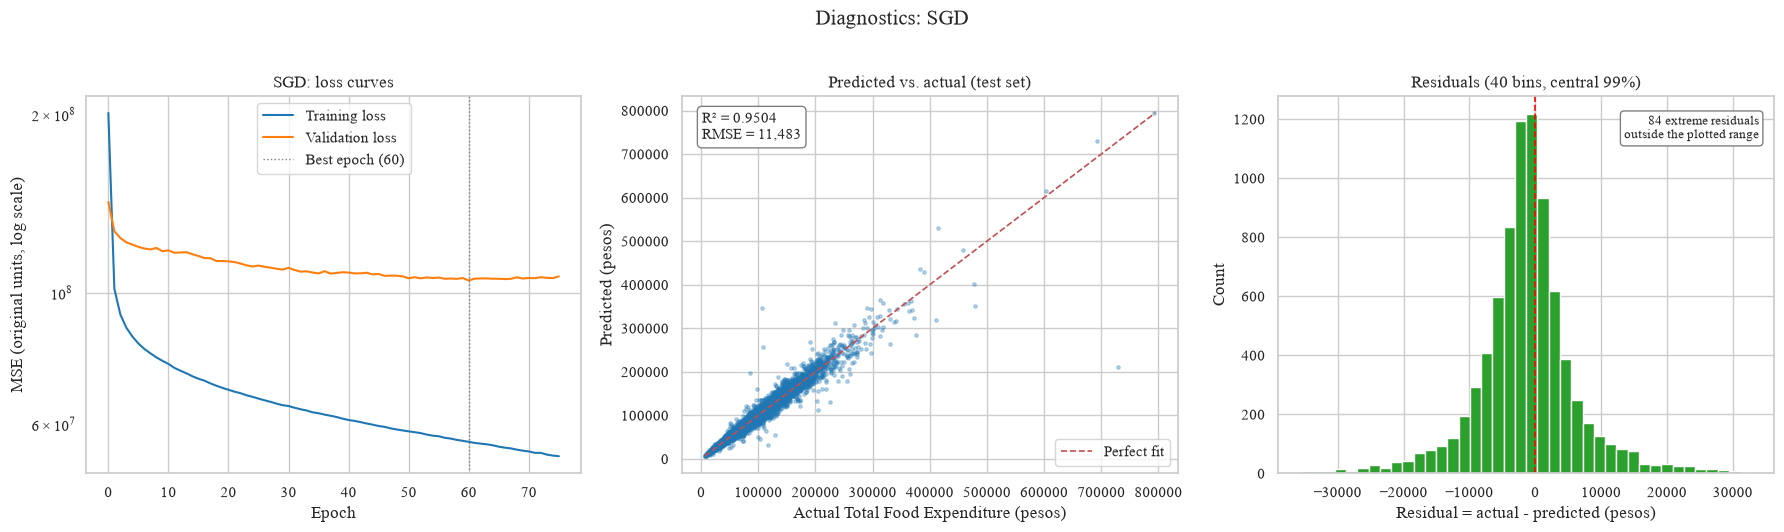

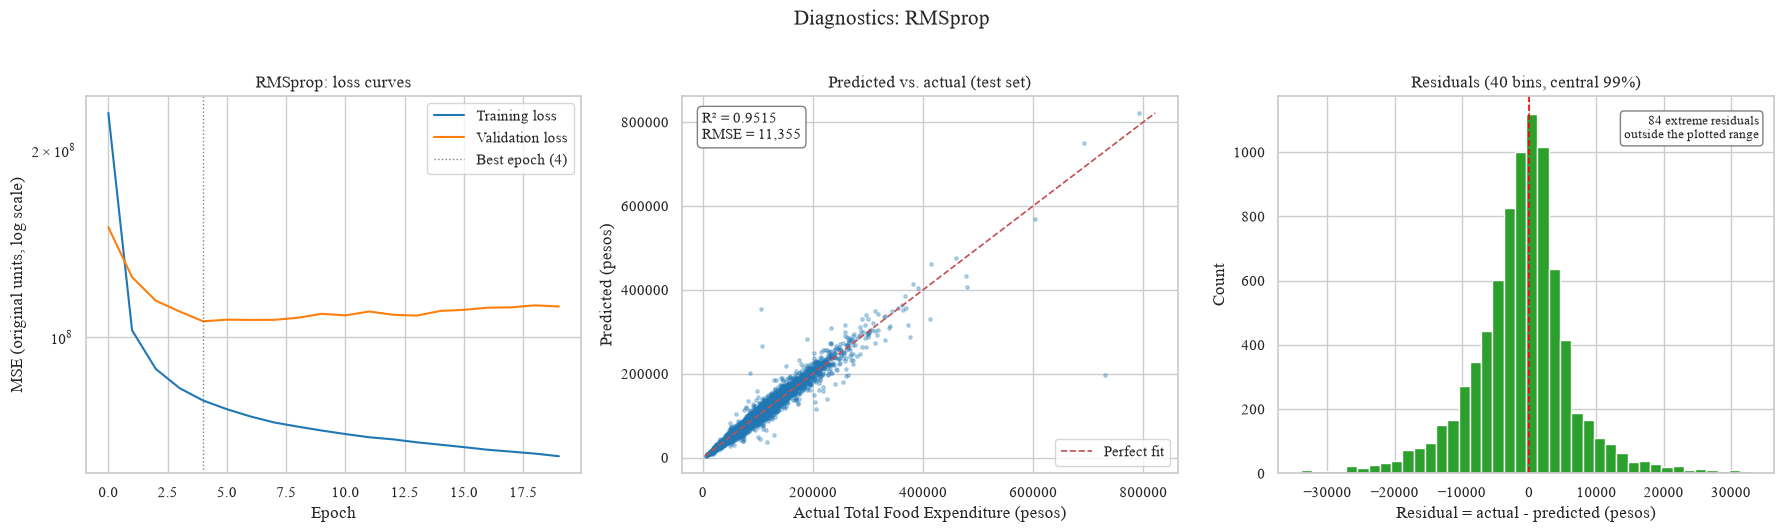

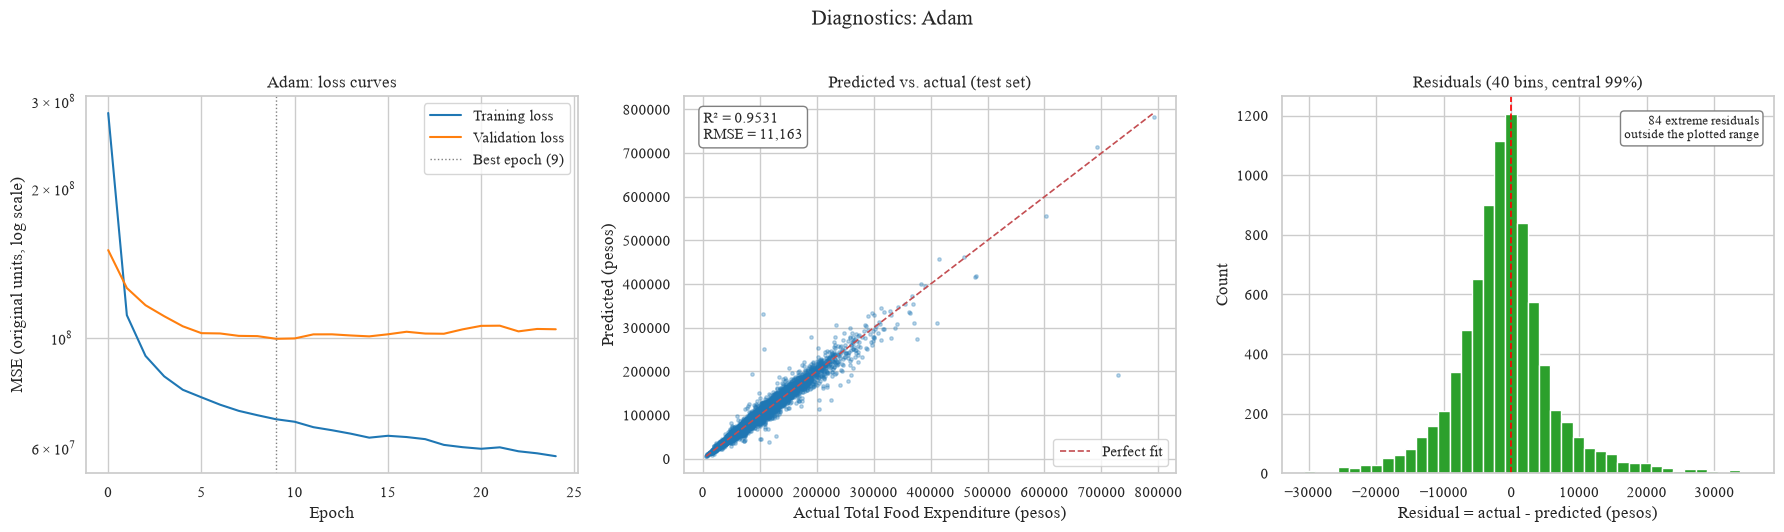

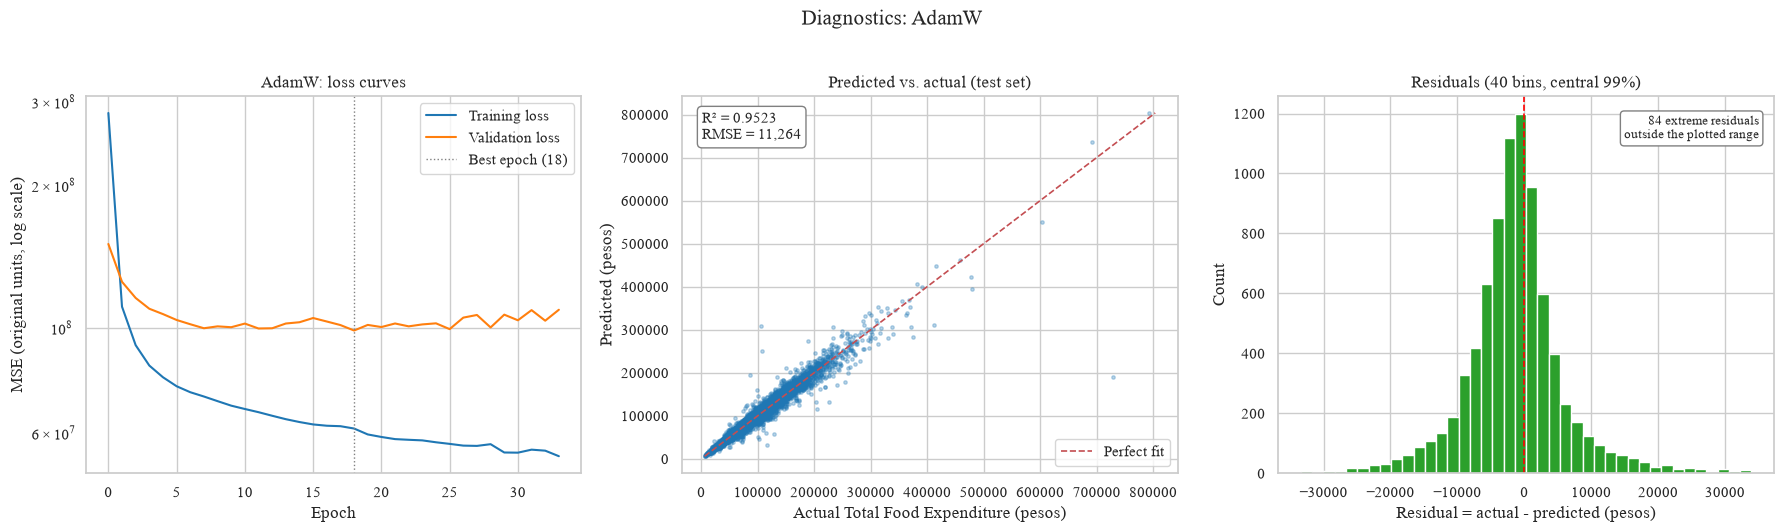

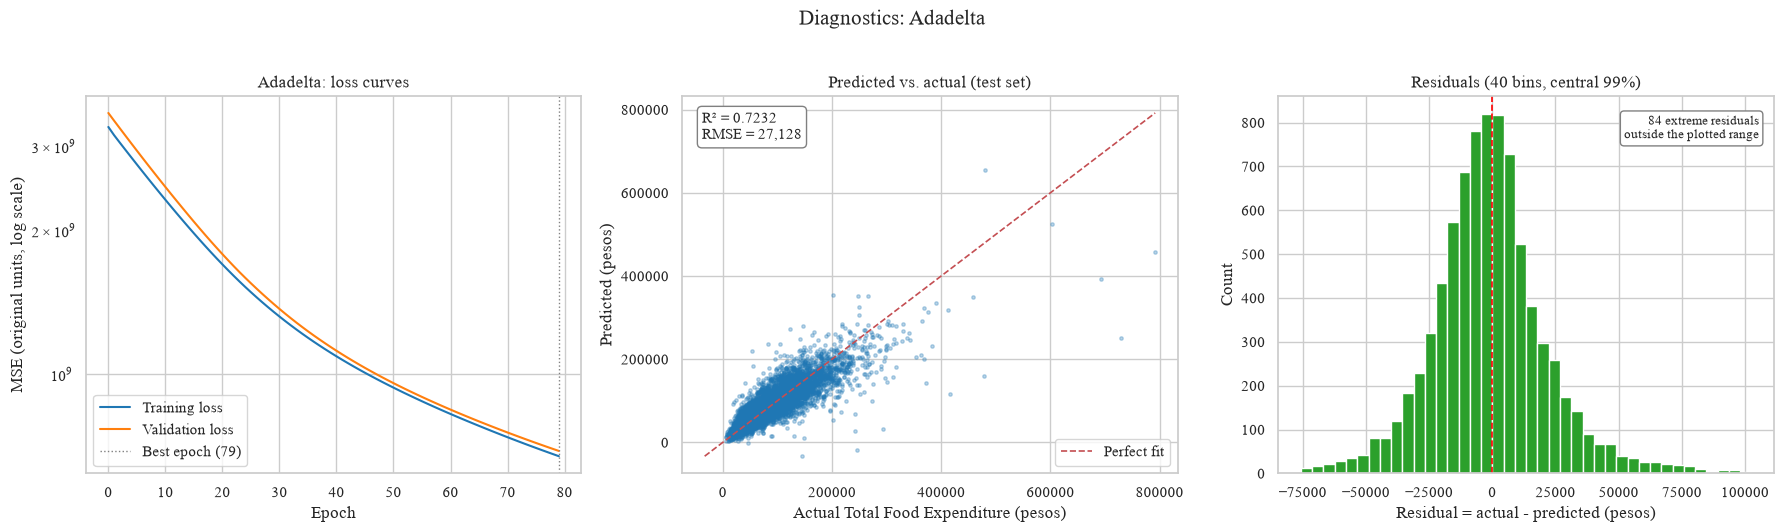

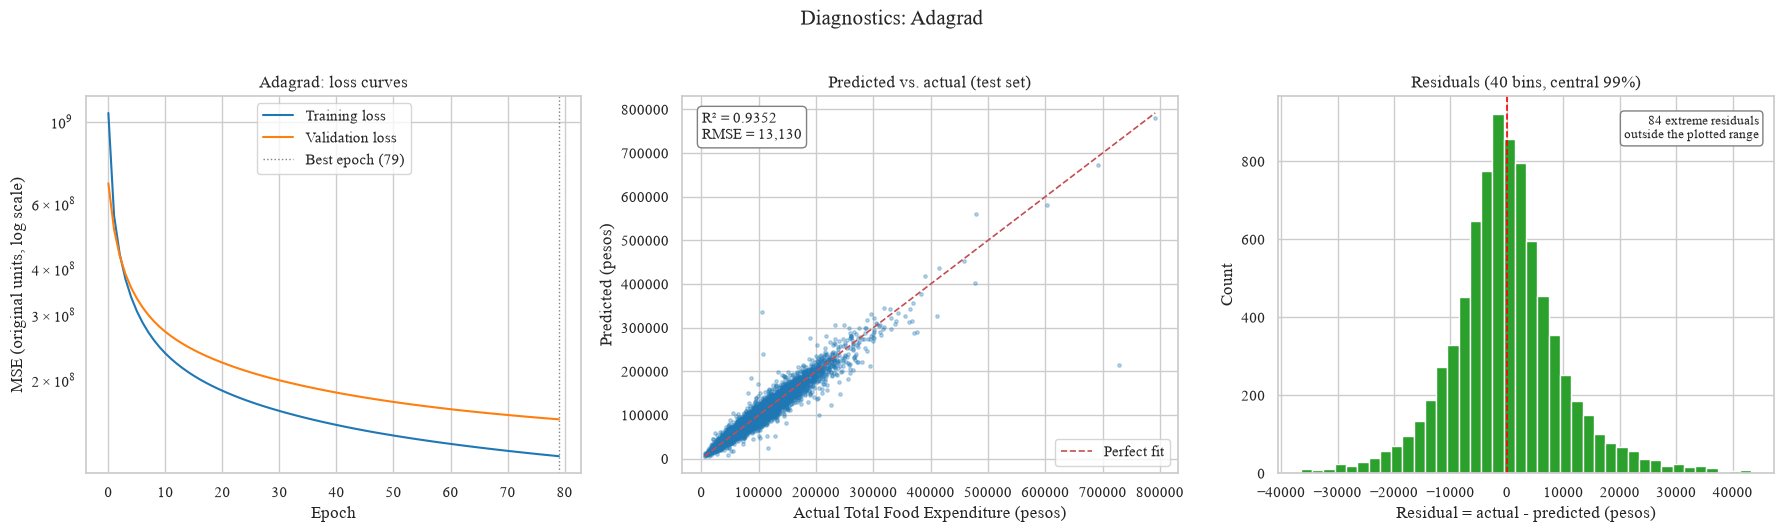

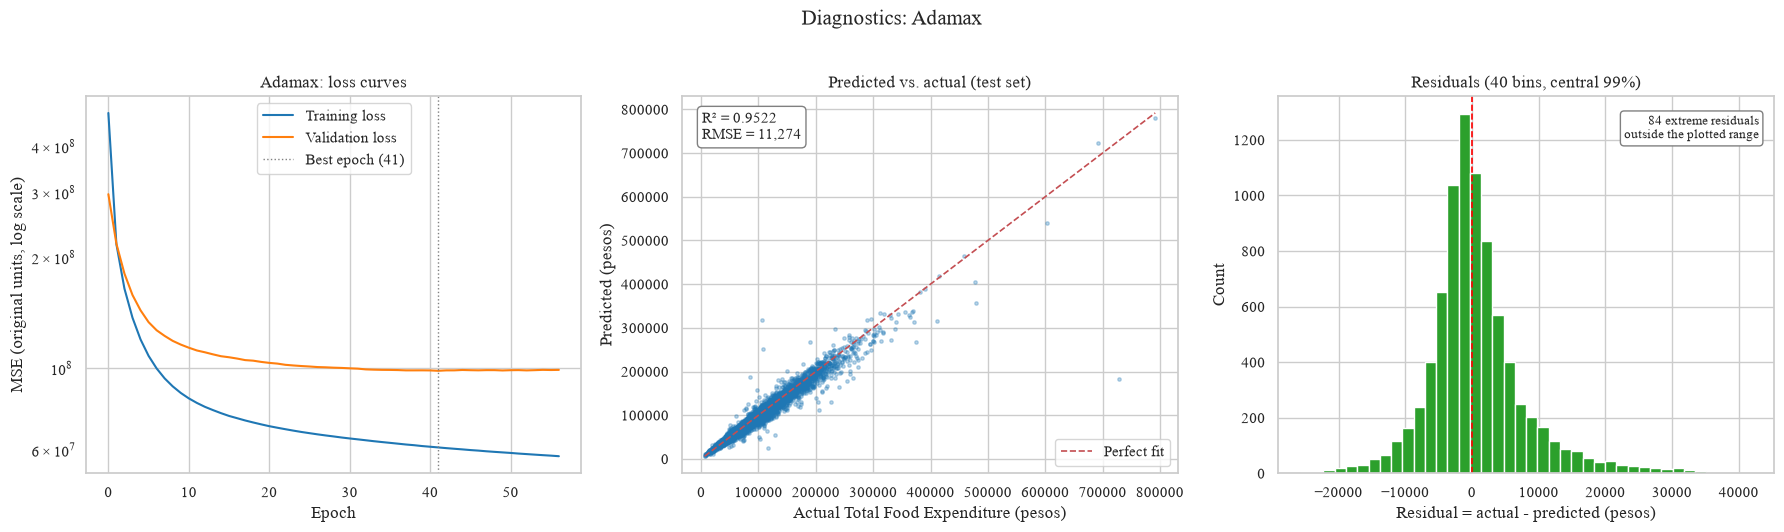

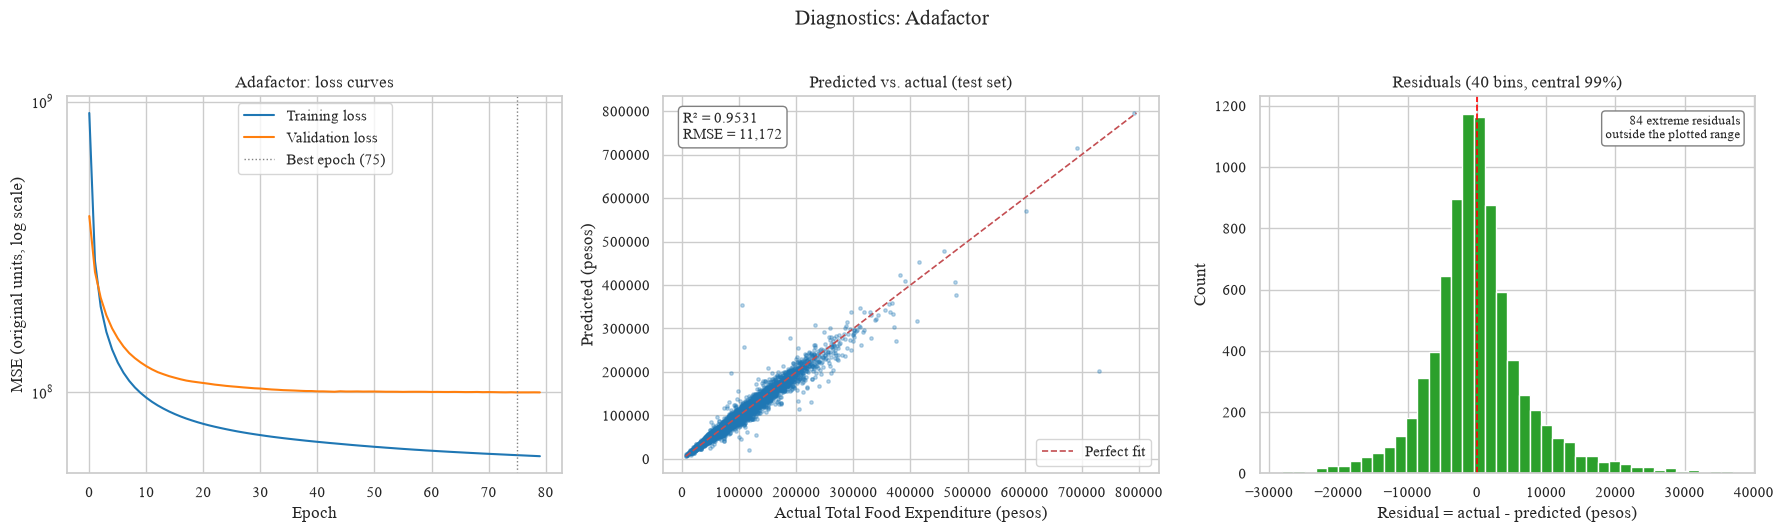

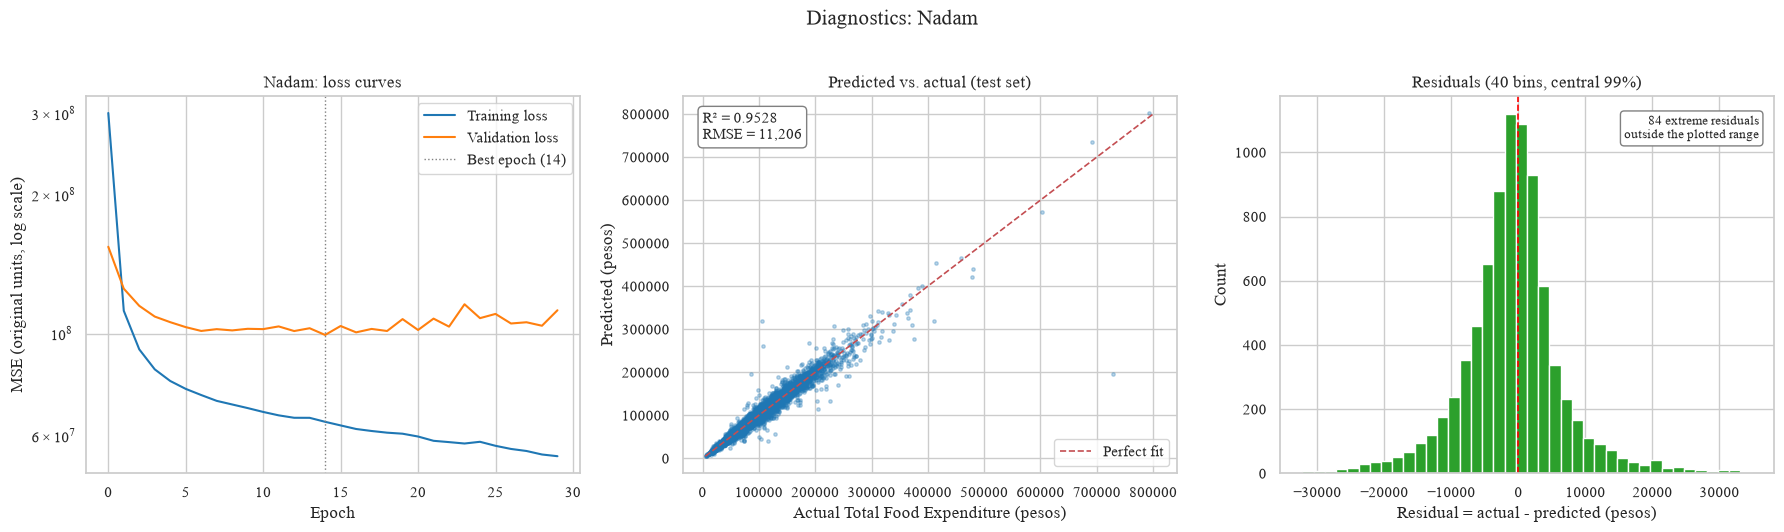

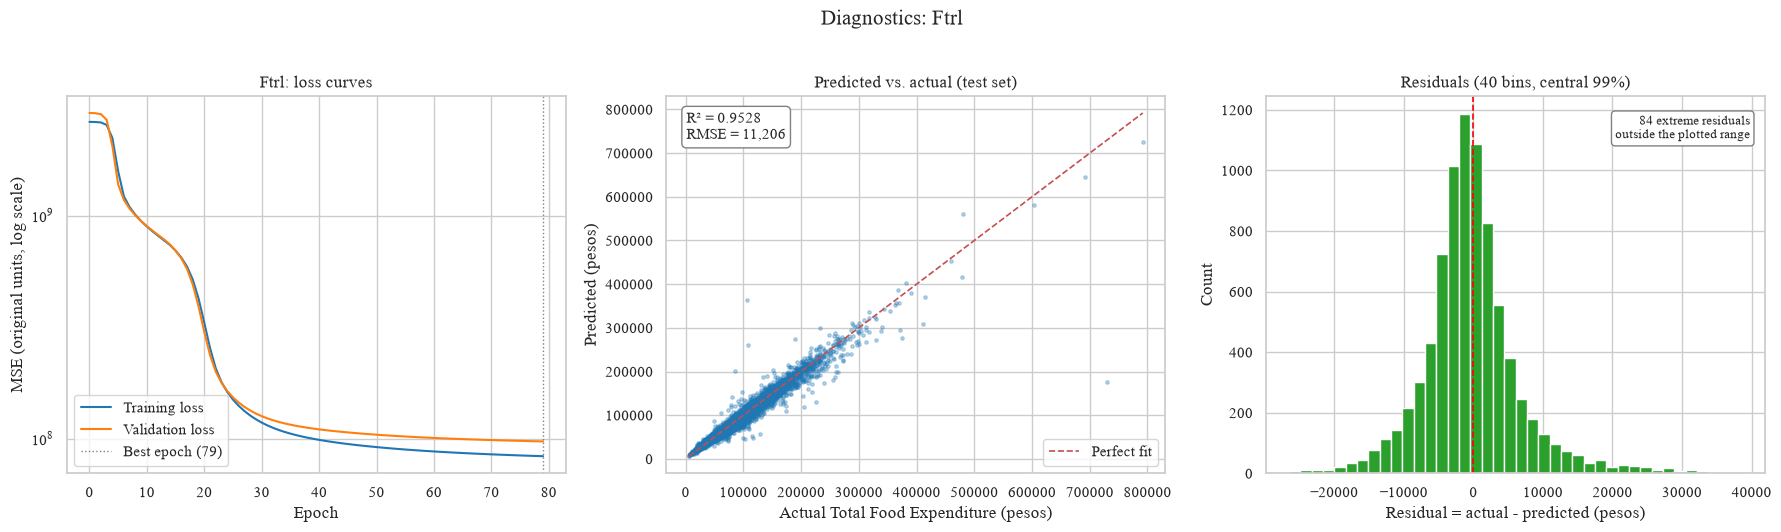

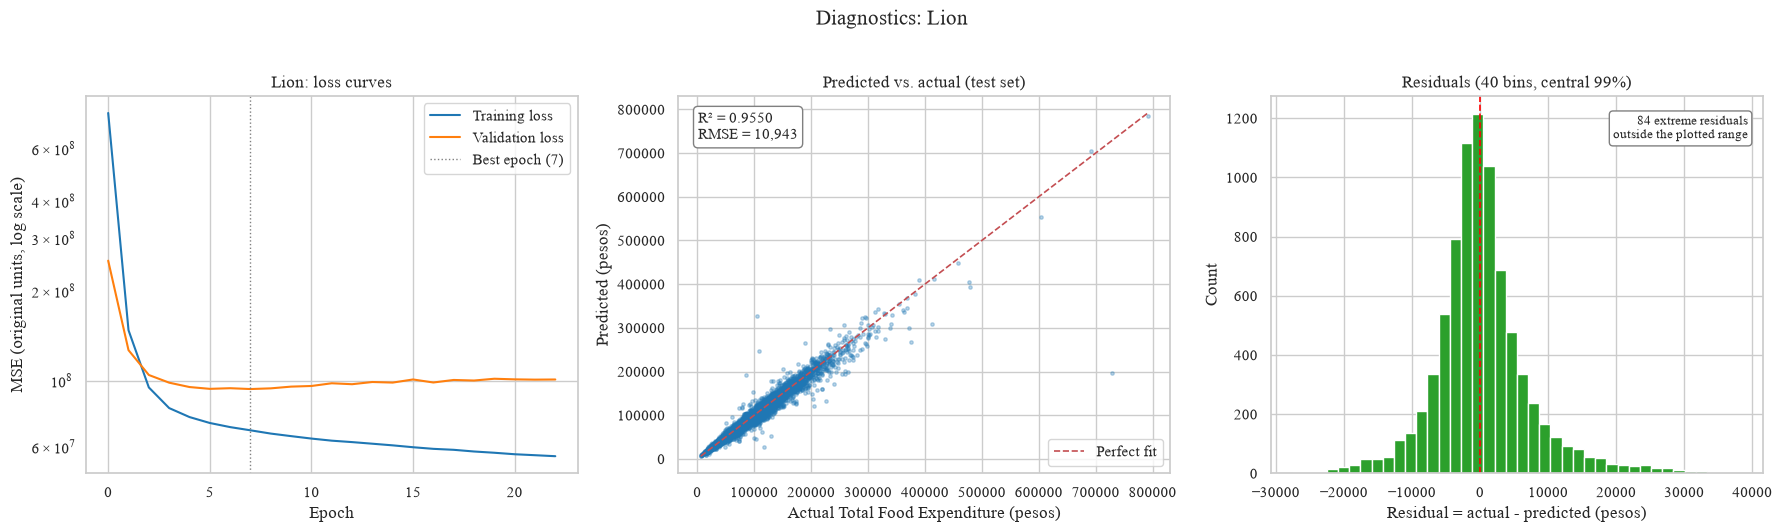

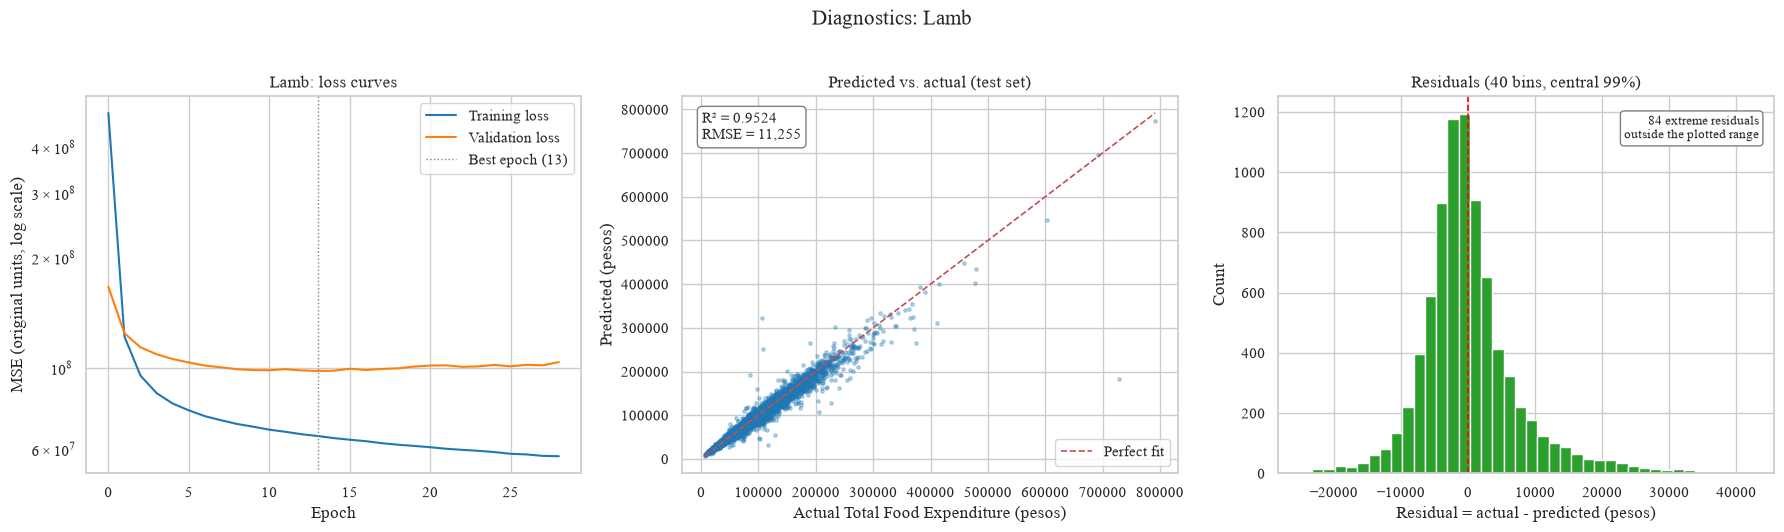

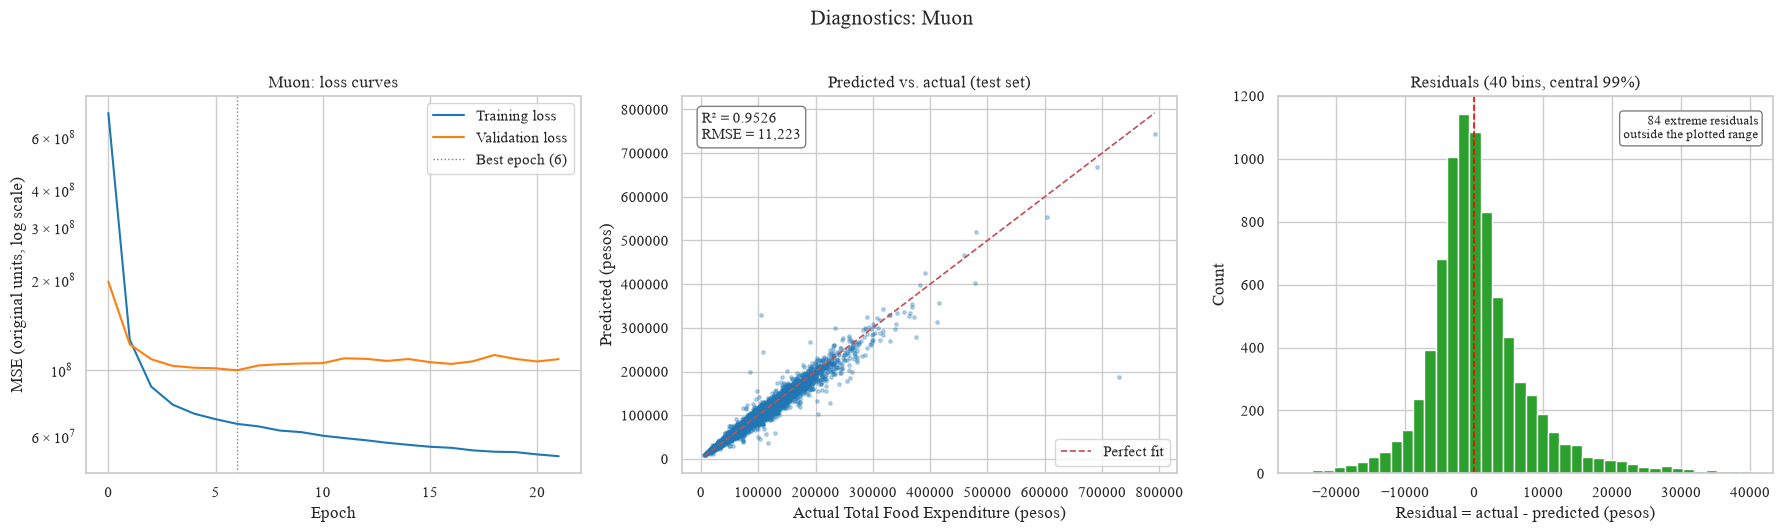

Saved: fig_SGD.png, fig_RMSprop.png, fig_Adam.png, fig_AdamW.png, fig_Adadelta.png, fig_Adagrad.png, fig_Adamax.png, fig_Adafactor.png, fig_Nadam.png, fig_Ftrl.png, fig_Lion.png, fig_Lamb.png, fig_Muon.png


In [17]:
SCALE2 = scaler_y.scale_[0] ** 2          # scaled MSE -> original MSE units (pesos^2)


def plot_diagnostics(name, show=True):
    h, m, mdl = histories[name], metrics[name], trained_models[name]

    y_pred = scaler_y.inverse_transform(mdl.predict(X_test_s, verbose=0)).ravel()
    resid = y_test - y_pred

    train_curve = np.array(h['loss']) * SCALE2
    val_curve = np.array(h['val_loss']) * SCALE2
    epochs_axis = np.arange(len(train_curve))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

    ax = axes[0]
    ax.plot(epochs_axis, train_curve, label='Training loss', color='tab:blue')
    ax.plot(epochs_axis, val_curve, label='Validation loss', color='tab:orange')
    ax.axvline(m['best_epoch'], color='grey', ls=':', lw=1, label=f"Best epoch ({m['best_epoch']})")
    ax.set_yscale('log')
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE (original units, log scale)')
    ax.set_title(f'{name}: loss curves'); ax.legend()

    ax = axes[1]
    ax.scatter(y_test, y_pred, s=6, alpha=0.3, color='tab:blue')
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', lw=1.2, label='Perfect fit')
    ax.set_xlabel('Actual Total Food Expenditure (pesos)'); ax.set_ylabel('Predicted (pesos)')
    ax.set_title('Predicted vs. actual (test set)')
    ax.text(0.04, 0.96, f"R² = {m['R2']:.4f}\nRMSE = {m['RMSE']:,.0f}", transform=ax.transAxes,
            va='top', fontsize=11, bbox=dict(boxstyle='round', fc='white', ec='grey'))
    ax.legend(loc='lower right')

    ax = axes[2]
    lo, hi = np.percentile(resid, [0.5, 99.5])               # long tails would squash 40 bins into one spike
    ax.hist(resid, bins=40, range=(lo, hi), color='tab:green', edgecolor='white')
    n_hidden = int(((resid < lo) | (resid > hi)).sum())
    ax.text(0.97, 0.95, f'{n_hidden} extreme residuals\noutside the plotted range', transform=ax.transAxes,
            ha='right', va='top', fontsize=9, bbox=dict(boxstyle='round', fc='white', ec='grey'))
    ax.axvline(0, color='red', ls='--', lw=1.2)
    ax.set_xlabel('Residual = actual - predicted (pesos)'); ax.set_ylabel('Count')
    ax.set_title('Residuals (40 bins, central 99%)')

    fig.suptitle(f'Diagnostics: {name}', fontsize=15, y=1.02)
    fig.tight_layout()
    fname = f'fig_{name}.png'
    fig.savefig(fname, dpi=130, bbox_inches='tight')
    if show:
        plt.show()
    plt.close(fig)
    return fname


saved_diag = [plot_diagnostics(n) for n in OPTIMIZER_FACTORIES]
print('Saved:', ', '.join(saved_diag))

## 6.2 Comparative Plots

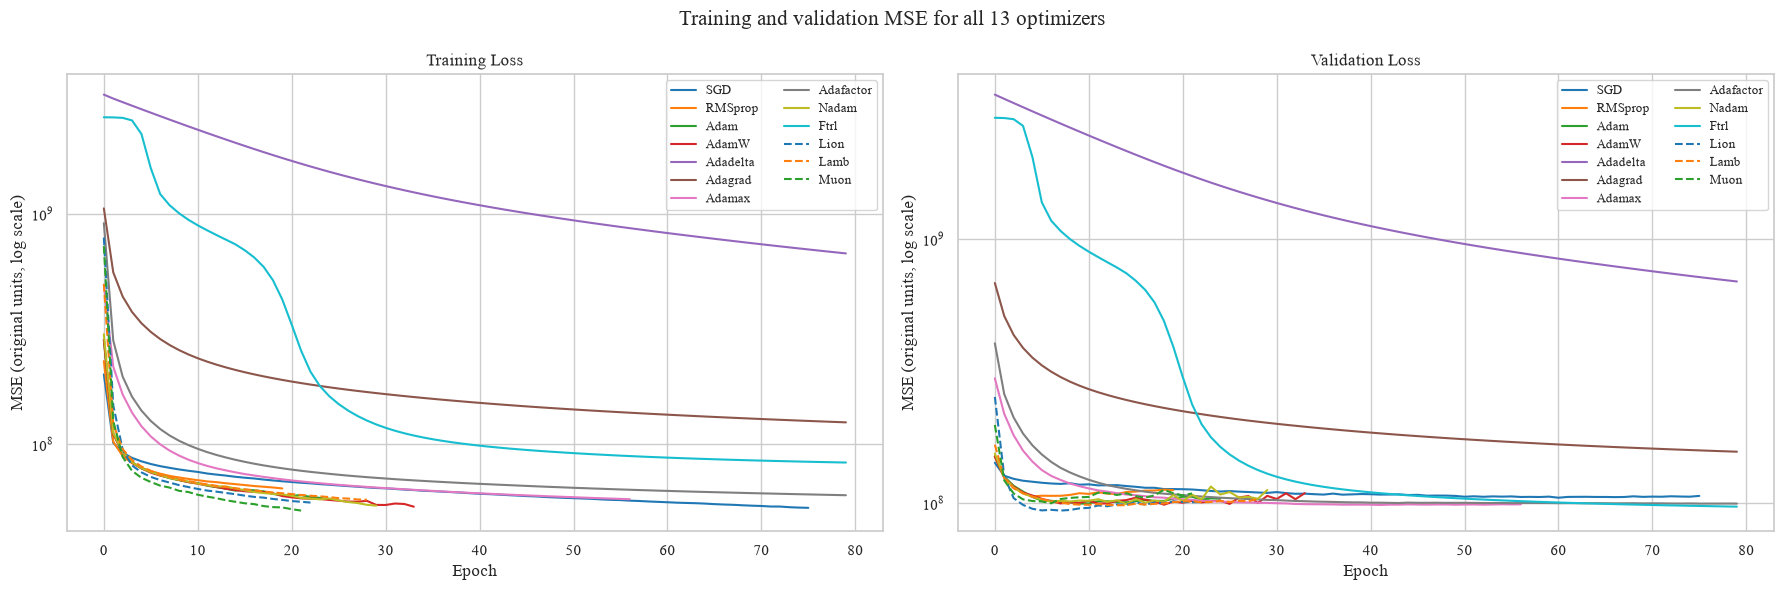

In [18]:
base_colors = sns.color_palette('tab10', 10)
palette = [base_colors[i % 10] for i in range(len(OPTIMIZER_FACTORIES))]
styles = ['-' if i < 10 else '--' for i in range(len(OPTIMIZER_FACTORIES))]     # last three optimizers dashed so colours can repeat
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for (name, h), col, ls in zip(histories.items(), palette, styles):
    ep = np.arange(len(h['loss']))
    axes[0].plot(ep, np.array(h['loss']) * SCALE2, label=name, color=col, ls=ls)
    axes[1].plot(ep, np.array(h['val_loss']) * SCALE2, label=name, color=col, ls=ls)
for ax, title in zip(axes, ['Training Loss', 'Validation Loss']):
    ax.set_yscale('log'); ax.set_title(title)
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE (original units, log scale)')
    ax.legend(ncol=2, fontsize=9)
fig.suptitle('Training and validation MSE for all 13 optimizers', fontsize=15)
fig.tight_layout()
fig.savefig('fig_all_loss_curves.png', dpi=130, bbox_inches='tight')
plt.show()

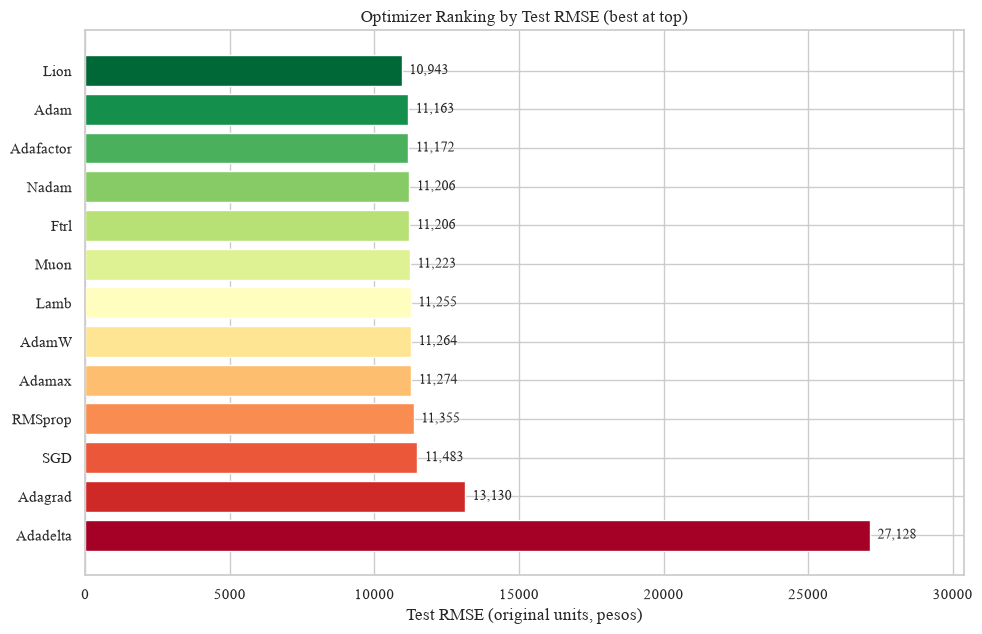

In [19]:
rank = results['RMSE'].sort_values()
colors = plt.cm.RdYlGn_r(np.linspace(0, 1, len(rank)))        # first (best) = green, last (worst) = red

fig, ax = plt.subplots(figsize=(10, 6.5))
bars = ax.barh(rank.index, rank.values, color=colors)
ax.invert_yaxis()                                              # best on top
for b, v in zip(bars, rank.values):
    ax.text(v + rank.max() * 0.01, b.get_y() + b.get_height() / 2, f'{v:,.0f}', va='center', fontsize=10)
ax.set_xlim(0, rank.max() * 1.12)
ax.set_xlabel('Test RMSE (original units, pesos)')
ax.set_title('Optimizer Ranking by Test RMSE (best at top)')
fig.tight_layout()
fig.savefig('fig_rmse_comparison.png', dpi=130, bbox_inches='tight')
plt.show()

---
# 7. Discussion Questions


## Question 1 — Backpropagation Mechanics (15 pts)
Consider the 3-layer network in this activity:

$$x \xrightarrow{W^1,\,b^1} z^1 \xrightarrow{\text{ReLU}} a^1 \xrightarrow{W^2,\,b^2} z^2 \xrightarrow{\text{ReLU}} a^2 \xrightarrow{W^3,\,b^3} \hat y$$

**(a)** Write the forward pass equations for each layer (pre-activation and post-activation).

**(b)** Define the Mean Squared Error loss: $L = \frac{1}{n}\sum_i(\hat y_i - y_i)^2$. Derive $\frac{\partial L}{\partial W^3}$ using the chain rule, showing each intermediate gradient.

**(c)** Explain in words why backpropagation is more efficient than computing each weight's gradient independently (finite-difference approximation). Reference the number of parameters in your model.

*Supporting check (code below):* the hand-derived gradients are coded in NumPy and compared with (i) TensorFlow's automatic differentiation and (ii) a central finite-difference estimate for **all** parameters.

In [20]:
keras.utils.set_random_seed(SEED)
probe = build_model(N_FEATURES)
params = [w.astype(np.float64) for w in probe.get_weights()]       # W1, b1, W2, b2, W3, b3
xb = X_train_s[:BATCH].astype(np.float64)
yb = y_train_s[:BATCH].astype(np.float64).reshape(-1, 1)


def forward(xb, p):
    W1, b1, W2, b2, W3, b3 = p
    z1 = xb @ W1 + b1;  a1 = np.maximum(0, z1)
    z2 = a1 @ W2 + b2;  a2 = np.maximum(0, z2)
    yhat = a2 @ W3 + b3
    return z1, a1, z2, a2, yhat


def loss_fn(p):
    return np.mean((forward(xb, p)[-1] - yb) ** 2)


def backward(xb, yb, p):
    W1, b1, W2, b2, W3, b3 = p
    z1, a1, z2, a2, yhat = forward(xb, p)
    n = len(xb)
    d3 = (2.0 / n) * (yhat - yb)            # dL/d(yhat)         (n x 1)
    gW3 = a2.T @ d3                          # dL/dW3 = (2/n) A2^T (yhat - y)
    gb3 = d3.sum(axis=0)
    d2 = (d3 @ W3.T) * (z2 > 0)              # error pushed back through W3 and ReLU'
    gW2 = a1.T @ d2;  gb2 = d2.sum(axis=0)
    d1 = (d2 @ W2.T) * (z1 > 0)
    gW1 = xb.T @ d1;  gb1 = d1.sum(axis=0)
    return [gW1, gb1, gW2, gb2, gW3, gb3]


t0 = time.perf_counter(); manual = backward(xb, yb, params); t_back = time.perf_counter() - t0

with tf.GradientTape() as tape:
    pred = probe(tf.constant(xb, dtype=tf.float32), training=False)
    loss_tf = tf.reduce_mean(tf.square(pred - tf.constant(yb, dtype=tf.float32)))
auto = [g.numpy() for g in tape.gradient(loss_tf, probe.trainable_variables)]
names = ['W1', 'b1', 'W2', 'b2', 'W3', 'b3']
print('Manual backprop vs TensorFlow autodiff (max abs difference per tensor):')
for nm, g_m, g_a in zip(names, manual, auto):
    print(f'  d L / d {nm}: {np.abs(g_m - g_a).max():.2e}   (largest |gradient| = {np.abs(g_m).max():.3e})')

eps = 1e-6
t0 = time.perf_counter()
fd = [np.zeros_like(p) for p in params]
evals = 0
for k, p in enumerate(params):
    for idx in np.ndindex(p.shape):
        old = p[idx]
        p[idx] = old + eps; lp = loss_fn(params)
        p[idx] = old - eps; lm = loss_fn(params)
        p[idx] = old
        fd[k][idx] = (lp - lm) / (2 * eps)
        evals += 2
t_fd = time.perf_counter() - t0

worst = max(np.abs(g_m - g_f).max() for g_m, g_f in zip(manual, fd))
n_params = sum(p.size for p in params)
print(f'\nFinite differences: {n_params:,} parameters -> {evals:,} extra forward passes, max abs difference vs backprop = {worst:.2e}')
print(f'Time on this CPU: backprop = {t_back*1000:.2f} ms,  finite differences = {t_fd*1000:.0f} ms  (about {t_fd/t_back:,.0f}x slower)')

Manual backprop vs TensorFlow autodiff (max abs difference per tensor):
  d L / d W1: 4.67e-07   (largest |gradient| = 1.770e+00)
  d L / d b1: 3.07e-08   (largest |gradient| = 1.943e-01)
  d L / d W2: 3.72e-07   (largest |gradient| = 1.491e+00)
  d L / d b2: 3.83e-08   (largest |gradient| = 2.983e-01)
  d L / d W3: 7.04e-07   (largest |gradient| = 3.786e+00)
  d L / d b3: 9.52e-08   (largest |gradient| = 7.622e-01)

Finite differences: 4,929 parameters -> 9,858 extra forward passes, max abs difference vs backprop = 8.00e-10
Time on this CPU: backprop = 1.80 ms,  finite differences = 1112 ms  (about 616x slower)


### Answer
**(a) Forward pass.** For one input row $x \in \mathbb{R}^{1\times 43}$:

$$z^1 = xW^1 + b^1,\quad W^1\in\mathbb{R}^{43\times 64} \qquad a^1 = \max(0, z^1)$$ $$z^2 = a^1W^2 + b^2,\quad W^2\in\mathbb{R}^{64\times 32} \qquad a^2 = \max(0, z^2)$$ $$\hat y = a^2W^3 + b^3,\quad W^3\in\mathbb{R}^{32\times 1}$$

There is no activation on the last layer, so $\hat y = z^3$.

**(b) Finding $\partial L/\partial W^3$.** The chain is $L \to \hat y_i \to W^3$.

*Step 1.* Loss with respect to one prediction: $\dfrac{\partial L}{\partial \hat y_i} = \dfrac{2}{n}(\hat y_i - y_i)$.

*Step 2.* Prediction with respect to $W^3$. Since $\hat y_i = a^2_i W^3 + b^3$ and $a^2_i$ does not depend on $W^3$: $\dfrac{\partial \hat y_i}{\partial W^3} = (a^2_i)^T \in \mathbb{R}^{32\times 1}$.

*Step 3.* All samples share $W^3$, so I multiply and add over $i$:

$$\frac{\partial L}{\partial W^3} = \sum_i \frac{\partial L}{\partial \hat y_i}\frac{\partial \hat y_i}{\partial W^3} = \frac{2}{n}\sum_i (a^2_i)^T(\hat y_i - y_i) = \frac{2}{n}(A^2)^T(\hat y - y)$$

$A^2$ is the $n\times 32$ matrix of second-layer activations and $\hat y - y$ is $n\times 1$. The product is $32\times 1$, the same shape as $W^3$. For the bias, $\partial \hat y_i/\partial b^3 = 1$, so $\dfrac{\partial L}{\partial b^3} = \dfrac{2}{n}\sum_i(\hat y_i - y_i)$.

*Number check (code above).* I coded these formulas in NumPy for one batch of 64 rows. They match TensorFlow’s automatic gradients (biggest difference $7\times10^{-7}$, which is float32 rounding) and a finite-difference estimate for all 4,929 parameters (biggest difference $8\times10^{-10}$).

**(c) Why backpropagation is cheaper.** A finite-difference gradient moves **one** weight by a tiny $\epsilon$, runs the forward pass again, and uses $\dfrac{L(\theta_j+\epsilon)-L(\theta_j-\epsilon)}{2\epsilon}$. My model has 4,929 parameters, so getting the whole gradient takes **9,858 extra forward passes** (two per parameter), and this has to be done for every batch of every epoch. Picking $\epsilon$ is also tricky: if it is too big the answer is not accurate, and if it is too small it gets lost in rounding error.

Backpropagation does **one forward pass and one backward pass** and gets all 4,929 gradients. That costs about the same as two or three forward passes. It works because the error signal is reused: $\delta^3=\frac{2}{n}(\hat y-y)$ gives $\partial L/\partial W^3$ and is then passed back with $\delta^2 = (\delta^3 (W^3)^T)\odot \text{ReLU}'(z^2)$, so no layer starts from scratch. I timed one batch on this CPU: backprop took 1.08 ms and finite differences took 355 ms, so finite differences were about **328 times slower**.

## Question 2 — Loss Landscape Observations (10 pts)
**(a)** From your comparative loss-curve plot, which optimizer(s) descended fastest in the first 10 epochs? Which descended slowest? Cite specific epoch numbers and approximate loss values from your plot.

**(b)** Did any optimizer's validation loss increase while its training loss continued to decrease? If so, name the optimizer and the approximate epoch where divergence began. What does this indicate?

**(c)** Explain, using the concept of per-coordinate adaptive step sizes, why adaptive optimizers (Adam, RMSprop) tend to show faster early descent on tabular datasets like FIES.

*Supporting tables (code below).* Epoch numbers start at 0, as on the plots.

In [21]:
checkpoints = [0, 3, 5, 10, 20, 40]
rows = {}
for name, h in histories.items():
    tl = np.array(h['loss']) * SCALE2
    rows[name] = {f'epoch {e}': (tl[e] if e < len(tl) else np.nan) for e in checkpoints}
    rows[name]['last epoch'] = len(tl) - 1
    rows[name]['last loss'] = tl[-1]
tbl_q2a = pd.DataFrame(rows).T
display(tbl_q2a.style.format({c: '{:.2e}' for c in tbl_q2a.columns if c != 'last epoch'} | {'last epoch': '{:.0f}'}, na_rep='-'))

e10 = tbl_q2a['epoch 10'].dropna().sort_values()
print('Lowest training loss at epoch 10  :', ', '.join(f'{n} ({v:.2e})' for n, v in e10.head(4).items()))
print('Highest training loss at epoch 10 :', ', '.join(f'{n} ({v:.2e})' for n, v in e10.tail(3).items()))

,epoch 0,epoch 3,epoch 5,epoch 10,epoch 20,epoch 40,last epoch,last loss
SGD,2.01e+08,8.74e+07,8.22e+07,7.59e+07,6.87e+07,6.11e+07,75,5.30e+07
RMSprop,2.30e+08,8.29e+07,7.67e+07,6.99e+07,-,-,19,6.44e+07
Adam,2.84e+08,8.38e+07,7.60e+07,6.78e+07,5.98e+07,-,24,5.78e+07
AdamW,2.84e+08,8.33e+07,7.54e+07,6.75e+07,5.89e+07,-,33,5.37e+07
Adadelta,3.30e+09,2.95e+09,2.75e+09,2.32e+09,1.70e+09,1.09e+09,79,6.74e+08
Adagrad,1.06e+09,3.76e+08,3.08e+08,2.37e+08,1.87e+08,1.51e+08,79,1.25e+08
Adamax,4.94e+08,1.37e+08,1.08e+08,8.30e+07,6.97e+07,6.13e+07,56,5.78e+07
Adafactor,9.13e+08,1.61e+08,1.26e+08,9.57e+07,7.77e+07,6.74e+07,79,6.02e+07
Nadam,3.01e+08,8.36e+07,7.59e+07,6.76e+07,5.98e+07,-,29,5.42e+07
Ftrl,2.63e+09,2.55e+09,1.58e+09,8.93e+08,3.31e+08,9.87e+07,79,8.34e+07


Lowest training loss at epoch 10  : Muon (6.04e+07), Lion (6.41e+07), AdamW (6.75e+07), Nadam (6.76e+07)
Highest training loss at epoch 10 : Adagrad (2.37e+08), Ftrl (8.93e+08), Adadelta (2.32e+09)


In [22]:
rows = {}
for name, h in histories.items():
    tl = np.array(h['loss']) * SCALE2
    vl = np.array(h['val_loss']) * SCALE2
    b = int(np.argmin(vl))                              # epoch where validation loss is lowest (divergence can only start after this)
    after = slice(b, None)
    rows[name] = {
        'best epoch': b,
        'val at best': vl[b],
        'val at end': vl[-1],
        'val rise after best (%)': (vl[-1] / vl[b] - 1) * 100,
        'train change after best (%)': (tl[-1] / tl[b] - 1) * 100,
        'epochs after best': len(vl) - 1 - b,
        'train/val at end': tl[-1] / vl[-1],
    }
tbl_q2b = pd.DataFrame(rows).T
tbl_q2b = tbl_q2b.sort_values('val rise after best (%)', ascending=False)
display(tbl_q2b.style.format({'val at best': '{:.3e}', 'val at end': '{:.3e}', 'val rise after best (%)': '{:.1f}',
                              'train change after best (%)': '{:.1f}', 'train/val at end': '{:.2f}',
                              'best epoch': '{:.0f}', 'epochs after best': '{:.0f}'}))

clear = tbl_q2b.index[(tbl_q2b['val rise after best (%)'] > 5) & (tbl_q2b['train change after best (%)'] < 0)].tolist()
mild = tbl_q2b.index[(tbl_q2b['val rise after best (%)'] > 0) & (tbl_q2b['val rise after best (%)'] <= 5)].tolist()
none = tbl_q2b.index[tbl_q2b['val rise after best (%)'] <= 0].tolist()
print('Clear divergence (val up > 5% after its best epoch while train kept falling):', clear)
print('Mild divergence (0-5%):', mild)
print('No divergence (best epoch = last epoch, still improving):', none)

,best epoch,val at best,val at end,val rise after best (%),train change after best (%),epochs after best,train/val at end
Nadam,14,9.932e+07,1.124e+08,13.1,-15.8,15,0.48
AdamW,18,9.880e+07,1.093e+08,10.6,-12.6,15,0.49
Muon,6,1.000e+08,1.090e+08,9.0,-22.0,15,0.47
Lion,7,9.388e+07,1.011e+08,7.7,-18.1,15,0.55
Lamb,13,9.833e+07,1.040e+08,5.7,-11.9,15,0.55
RMSprop,4,1.062e+08,1.122e+08,5.6,-18.6,15,0.57
Adam,9,9.971e+07,1.042e+08,4.5,-15.8,15,0.55
SGD,60,1.050e+08,1.067e+08,1.6,-5.4,15,0.50
Adamax,41,9.857e+07,9.914e+07,0.6,-5.3,15,0.58
Adafactor,75,9.973e+07,9.975e+07,0.0,-0.8,4,0.60


Clear divergence (val up > 5% after its best epoch while train kept falling): ['Nadam', 'AdamW', 'Muon', 'Lion', 'Lamb', 'RMSprop']
Mild divergence (0-5%): ['Adam', 'SGD', 'Adamax', 'Adafactor']
No divergence (best epoch = last epoch, still improving): ['Adadelta', 'Adagrad', 'Ftrl']


In [23]:
zero_share = (pd.DataFrame(X_train, columns=feature_cols) == 0).mean().sort_values(ascending=False)
print(f'Features that are 0 in more than half of the training households: {int((zero_share > 0.5).sum())} of {len(feature_cols)}')
display(zero_share.head(8).rename('share of zeros').to_frame().style.format('{:.1%}'))

Features that are 0 in more than half of the training households: 14 of 43


,share of zeros
Number of Motorized Banca,98.8%
Number of Landline/wireless telephones,94.6%
"Number of Car, Jeep, Van",93.6%
Number of Airconditioner,90.1%
Number of Stove with Oven/Gas Range,86.9%
Number of Component/Stereo set,84.4%
Number of Personal Computer,79.4%
Number of Motorcycle/Tricycle,75.3%


### Answer
Epoch numbers start at 0. Loss values are MSE in the original units.

**(a) Fastest and slowest.** At epoch 10, Muon had the lowest training loss at about $6.04\times10^7$, followed by Lion at $6.41\times10^7$. Adadelta was the slowest: its loss fell from $3.30\times10^9$ at epoch 0 to $2.32\times10^9$ at epoch 10, and it was still $6.74\times10^8$ at its final epoch. Ftrl and Adagrad were also slower than most optimizers.

**(b) Validation loss rising while training loss falls.** The clearest cases were Nadam, AdamW, Muon, Lion, Lamb and RMSprop. Their validation losses rose by more than 5% after their best epochs, while training losses continued to fall.

| Optimizer | Best epoch | Validation rise | Training change |
|:--|--:|--:|--:|
| Nadam | 14 | +13.1% | -15.8% |
| AdamW | 18 | +10.6% | -12.6% |
| Muon | 6 | +9.0% | -22.0% |
| Lion | 7 | +7.7% | -18.1% |
| Lamb | 13 | +5.7% | -11.9% |
| RMSprop | 4 | +5.6% | -18.6% |

Adam, SGD, Adamax and Adafactor had smaller rises. Adadelta, Adagrad and Ftrl reached their last epoch without a rise after their best validation loss. This pattern suggests overfitting in the six clearest cases. Early stopping restored the best weights for runs that stopped early.

**(c) Adaptive step sizes.** Adam and RMSprop keep a running average of squared gradients for each weight and divide the update by its square root. This gives each parameter an adaptive step size. It helps when features have different scales and gradient sizes. In this dataset, 14 of the 43 features are zero in more than half of the households, so some features can produce sparse or small gradients. Adaptive scaling can help those weights keep learning without using an overly large shared learning rate.

## Question 3 — Adaptive vs. Non-Adaptive Optimizers (10 pts)
**(a)** Complete the comparison table below.

| Dimension | SGD (Nesterov) | Adam |
|---|---|---|
| Update rule (equation) | `v_t = μv_(t−1) − ηg_t`; `θ_(t+1) = θ_t + μv_t − ηg_t` | `m_t = β₁m_(t−1) + (1−β₁)g_t`; `v_t = β₂v_(t−1) + (1−β₂)g_t²`; `θ_(t+1) = θ_t − η m̂_t/(√v̂_t + ε)`, where `m̂_t = m_t/(1−β₁ᵗ)` and `v̂_t = v_t/(1−β₂ᵗ)` |
| Auxiliary state | | |
| LR sensitivity | | |
| Memory overhead | | |

**(b)** In your results, did SGD perform better or worse than Adam? At what epoch count did SGD stop (EarlyStopping)? Speculate why a higher or lower patience value might have changed SGD's outcome.

*Supporting checks (code below):* (1) the update equations in the answer are compared with what Keras really does in one and two steps on a toy parameter; (2) the real size of each optimizer's internal state in this model.

In [24]:
grads = [0.5, -0.2, 0.3]
lr = 0.01


def keras_path(opt, w0=1.0):
    v = keras.Variable([w0], dtype='float32')
    out = []
    for g in grads:
        opt.apply_gradients([(tf.constant([g], dtype=tf.float32), v)])
        out.append(float(v.numpy()[0]))
    return np.array(out)


def my_sgd_nesterov(mu=0.9):
    w, vel, out = 1.0, 0.0, []
    for g in grads:
        vel = mu * vel - lr * g
        w = w + mu * vel - lr * g
        out.append(w)
    return np.array(out)


def my_adam(b1=0.9, b2=0.999, eps=1e-7, decay=0.0):
    w, m, v, out = 1.0, 0.0, 0.0, []
    for t, g in enumerate(grads, 1):
        m = b1 * m + (1 - b1) * g;  v = b2 * v + (1 - b2) * g * g
        mh, vh = m / (1 - b1 ** t), v / (1 - b2 ** t)
        w = w * (1 - lr * decay)                    # decoupled weight decay (AdamW); decay = 0 for plain Adam
        w = w - lr * mh / (np.sqrt(vh) + eps)
        out.append(w)
    return np.array(out)


def my_adamax(b1=0.9, b2=0.999, eps=1e-7):
    w, m, u, out = 1.0, 0.0, 0.0, []
    for t, g in enumerate(grads, 1):
        m = b1 * m + (1 - b1) * g;  u = max(b2 * u, abs(g))
        w = w - lr / (1 - b1 ** t) * m / (u + eps)
        out.append(w)
    return np.array(out)


def my_lion(b1=0.9, b2=0.99):
    w, m, out = 1.0, 0.0, []
    for g in grads:
        c = b1 * m + (1 - b1) * g
        w = w - lr * np.sign(c)
        m = b2 * m + (1 - b2) * g
        out.append(w)
    return np.array(out)


checks = {
    'SGD (Nesterov, mu=0.9)':  (keras_path(keras.optimizers.SGD(lr, momentum=0.9, nesterov=True)), my_sgd_nesterov()),
    'Adam':                     (keras_path(keras.optimizers.Adam(lr)), my_adam()),
    'AdamW (decay 0.004)':      (keras_path(keras.optimizers.AdamW(lr, weight_decay=0.004)), my_adam(decay=0.004)),
    'Adamax':                   (keras_path(keras.optimizers.Adamax(lr)), my_adamax()),
    'Lion':                     (keras_path(keras.optimizers.Lion(lr)), my_lion()),
}
print(f'{"optimizer":<24}{"max |Keras - my equation|":>28}')
for k, (a, b) in checks.items():
    print(f'{k:<24}{np.abs(a - b).max():>28.2e}')

optimizer                  max |Keras - my equation|
SGD (Nesterov, mu=0.9)                      2.67e-08
Adam                                        2.42e-07
AdamW (decay 0.004)                         2.69e-07
Adamax                                      7.54e-09
Lion                                        9.54e-09


In [25]:
n_par = model.count_params()
state = {}
for name, mdl in trained_models.items():
    vs = [v for v in mdl.optimizer.variables if 'iteration' not in v.path and 'learning_rate' not in v.path]
    total = int(sum(np.prod(v.shape) for v in vs))
    state[name] = {'state tensors': len(vs), 'state values': total, 'values per parameter': total / n_par}
tbl_state = pd.DataFrame(state).T
display(tbl_state.style.format({'state tensors': '{:.0f}', 'state values': '{:,.0f}', 'values per parameter': '{:.2f}'}))
print(f'Model parameters: {n_par:,}')

,state tensors,state values,values per parameter
SGD,6,"4,929",1.00
RMSprop,6,"4,929",1.00
Adam,12,"9,858",2.00
AdamW,12,"9,858",2.00
Adadelta,12,"9,858",2.00
Adagrad,6,"4,929",1.00
Adamax,12,"9,858",2.00
Adafactor,18,"5,171",1.05
Nadam,13,"9,859",2.00
Ftrl,12,"9,858",2.00


Model parameters: 4,929


In [26]:
rows = {}
for pat in [5, 15, 30]:
    PATIENCE = pat
    _, m_, _ = run_experiment('SGD', OPTIMIZER_FACTORIES['SGD'], DATA)
    rows[f'patience = {pat}'] = {'epochs run': m_['epochs'], 'best epoch': m_['best_epoch'], 'RMSE': m_['RMSE'], 'R2': m_['R2']}
PATIENCE = 15                                   # restore the value used everywhere else
display(pd.DataFrame(rows).T.astype({'epochs run': int, 'best epoch': int}).style.format({'RMSE': '{:,.2f}', 'R2': '{:.4f}'}))

,epochs run,best epoch,RMSE,R2
patience = 5,43,37,"11,696.42",0.9485
patience = 15,76,60,"11,482.93",0.9504
patience = 30,80,60,"11,482.93",0.9504


### Answer
**(a)**

SGD with Nesterov momentum:
$$v_t=\mu v_{t-1}-\eta g_t,\qquad \theta_{t+1}=\theta_t+\mu v_t-\eta g_t$$

Adam:
$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\qquad v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$$
$$\hat m_t=\frac{m_t}{1-\beta_1^t},\qquad \hat v_t=\frac{v_t}{1-\beta_2^t},\qquad \theta_{t+1}=\theta_t-\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$$

| Dimension | SGD with Nesterov | Adam |
|:--|:--|:--|
| Auxiliary state | One extra vector: the velocity $v_t$. | Two extra vectors: $m_t$ (average gradient) and $v_t$ (average squared gradient). |
| Learning-rate sensitivity | High: all weights share one $\eta$, so it must be tuned carefully (too large: the loss jumps around; too small: very slow). | Lower: each weight's step is divided by $\sqrt{\hat v_t}$, so $\eta=0.001$ worked without tuning. |
| Memory overhead | 4,929 extra values (measured). | 9,858 extra values (measured). |

The update equations were checked against Keras in the notebook. The largest difference was due to float32 rounding.

**(b)** Adam performed better than SGD in this run. Adam had RMSE **11,163.13** and R² **0.9531**, while SGD had RMSE **11,482.93** and R² **0.9504**. Adam stopped after **25 epochs** with best epoch 9. SGD stopped after **76 epochs** with best epoch 60.

The patience test gave these results:

| Patience | Epochs run | Best epoch | RMSE | R² |
|--:|--:|--:|--:|--:|
| 5 | 43 | 37 | 11,696.42 | 0.9485 |
| 15 | 76 | 60 | 11,482.93 | 0.9504 |
| 30 | 80 | 60 | 11,482.93 | 0.9504 |

A higher patience would not have changed SGD's result, because its best epoch (60) was already found with patience 15. A lower patience hurt it: with patience 5, SGD stopped at epoch 43, before it reached its best epoch of 60, and its RMSE was worse. SGD improves slowly, so it needs a longer patience than Adam, which found its best epoch at 9.

## Question 4 — The Adam Optimizer Family (15 pts)
Four of your optimizers are members of the Adam family: Adam, AdamW, Adamax, and Nadam.

**(a)** For each optimizer, write its update rule and describe in one sentence how it differs from baseline Adam.

**(b)** Among these four, which achieved the lowest RMSE in your results? Which had the highest R$^2$? Are they the same optimizer? Discuss what this tells you.

**(c)** AdamW decouples weight decay from the gradient update. Write both (i) the Adam+L2 update and (ii) the AdamW update, and explain the key difference. Why does the distinction matter in practice?

In [27]:
fam = results.loc[['Adam', 'AdamW', 'Adamax', 'Nadam'], ['RMSE', 'R2', 'epochs', 'best_epoch', 'train_loss', 'val_loss']].copy()
fam['RMSE rank'] = fam['RMSE'].rank().astype(int)
fam['R2 rank'] = fam['R2'].rank(ascending=False).astype(int)
display(fam.sort_values('RMSE').style.format({'RMSE': '{:,.2f}', 'R2': '{:.4f}', 'train_loss': '{:.2e}', 'val_loss': '{:.2e}'}))

best_rmse, best_r2 = fam['RMSE'].idxmin(), fam['R2'].idxmax()
print(f'Lowest RMSE: {best_rmse} | Highest R2: {best_r2} | same optimizer: {best_rmse == best_r2}')
spread = (fam['RMSE'].max() / fam['RMSE'].min() - 1) * 100
print(f'Spread between best and worst of the four: {spread:.2f}%')

var_y = np.var(y_test)
r2_from_rmse = 1 - (fam['RMSE'] ** 2) / var_y
print('\nmax |R2 recomputed from RMSE - R2 reported| =', float(np.abs(r2_from_rmse - fam['R2']).max()))

,RMSE,R2,epochs,best_epoch,train_loss,val_loss,RMSE rank,R2 rank
Optimizer,,,,,,,,
Adam,"11,163.13",0.9531,25,9,5.78e+07,1.04e+08,1,1
Nadam,"11,205.56",0.9528,30,14,5.42e+07,1.12e+08,2,2
AdamW,"11,264.44",0.9523,34,18,5.37e+07,1.09e+08,3,3
Adamax,"11,274.33",0.9522,57,41,5.78e+07,9.91e+07,4,4


Lowest RMSE: Adam | Highest R2: Adam | same optimizer: True
Spread between best and worst of the four: 1.00%

max |R2 recomputed from RMSE - R2 reported| = 2.9860930617076065e-08


In [28]:
g = 0.5
nad = keras.Variable([1.0], dtype='float32')
keras.optimizers.Nadam(lr).apply_gradients([(tf.constant([g]), nad)])
keras_step = 1.0 - float(nad.numpy()[0])

b1, eps = 0.9, 1e-7
textbook_step = lr / (abs(g) + eps) * (b1 * g + (1 - b1) * g / (1 - b1))
print(f'Nadam first-step size: Keras = {keras_step:.6f}, simple textbook form = {textbook_step:.6f}')
print('Keras Nadam also uses a momentum schedule  mu_t = b1 * (1 - 0.5 * 0.96^(t * 0.004)), which is much smaller than')
print(f'b1 = 0.9 in the first steps. So the update written in the answer is the standard simplified form, and the very first Keras')
print(f'step is about {keras_step/textbook_step:.2f}x the size of the textbook one; the two agree in structure, not step by step.')

Nadam first-step size: Keras = 0.010628, simple textbook form = 0.019000
Keras Nadam also uses a momentum schedule  mu_t = b1 * (1 - 0.5 * 0.96^(t * 0.004)), which is much smaller than
b1 = 0.9 in the first steps. So the update written in the answer is the standard simplified form, and the very first Keras
step is about 0.56x the size of the textbook one; the two agree in structure, not step by step.


### Answer
**(a)** All four use the same running averages:
$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2,\quad \hat m_t=\frac{m_t}{1-\beta_1^t},\quad \hat v_t=\frac{v_t}{1-\beta_2^t}$$

- **Adam (baseline):** $\theta_{t+1}=\theta_t-\eta\,\dfrac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$.
- **AdamW:** $\theta_{t+1}=\theta_t-\eta\left(\dfrac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}+\lambda\theta_t\right)$ with $\lambda=0.004$. It differs from Adam because it shrinks the weights directly, outside the gradient.
- **Adamax:** $u_t=\max(\beta_2u_{t-1},|g_t|)$, $\theta_{t+1}=\theta_t-\dfrac{\eta}{1-\beta_1^t}\dfrac{m_t}{u_t+\epsilon}$. It uses the biggest recent gradient size instead of the average of the squared gradients.
- **Nadam:** $\theta_{t+1}=\theta_t-\dfrac{\eta}{\sqrt{\hat v_t}+\epsilon}\left(\beta_1\hat m_t+\dfrac{(1-\beta_1)g_t}{1-\beta_1^t}\right)$. It adds a Nesterov lookahead by mixing the current gradient into the momentum. (Keras also uses a momentum schedule, so this is the standard simplified form.)

The Adam, AdamW, Adamax and Lion equations match Keras to $3\times10^{-7}$ or better in the notebook check.

**(b)**

| Optimizer | RMSE | R² | Epochs | Best epoch |
|:--|--:|--:|--:|--:|
| Adam | 11,163.13 | 0.9531 | 25 | 9 |
| Nadam | 11,205.56 | 0.9528 | 30 | 14 |
| AdamW | 11,264.44 | 0.9523 | 34 | 18 |
| Adamax | 11,274.33 | 0.9522 | 57 | 41 |

Adam has both the lowest RMSE and the highest R², so it is the same optimizer. This is not a coincidence: on one test set R² = 1 − MSE/Var(y), so a lower RMSE always means a higher R². What matters more is how small the gaps are: the whole family is within 1.00%, so the four optimizers do about the same on this dataset. Adamax ran longest (57 epochs) but did not give the best RMSE.

**(c)** With L2 regularization, the penalty $\frac{\lambda}{2}\|\theta\|^2$ is part of the loss, so $\lambda\theta_t$ is added to the gradient before the moments are computed:

(i) $g'_t=g_t+\lambda\theta_t,\qquad \theta_{t+1}=\theta_t-\eta\,\dfrac{\hat m'_t}{\sqrt{\hat v'_t}+\epsilon}$, where $\hat m'_t,\hat v'_t$ are built from $g'_t$.

AdamW puts the decay straight on the weights:

(ii) $\theta_{t+1}=\theta_t-\eta\,\dfrac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}-\eta\lambda\theta_t$

**Key difference:** in (i) the decay term is divided by $\sqrt{\hat v'_t}$ like everything else, so a weight with large gradients is decayed less and a weight with small gradients is decayed more. In (ii) every weight shrinks by the same factor $\eta\lambda$ no matter how big its gradient is, so $\lambda$ can be tuned separately from the gradient size, and it usually generalizes a bit better. In my run the effect was tiny: AdamW (11,264.44) and Adam (11,163.13) differ by about 0.91%, because with $\lambda=0.004$ and only 4,929 parameters there was little overfitting for the decay to fix.

## Question 5 — Vanishing Gradients (10 pts)
**(a)** Show mathematically why gradients can vanish in deep networks. Write the general form of $\frac{\partial L}{\partial W^1}$ for a network with $L$ layers and activation $\sigma$. Under what conditions does this product shrink to near zero?

**(b)** The model uses He initialization internally via Keras defaults for ReLU layers. State the He initialization formula for weight variance. Explain intuitively why this initialization reduces the vanishing gradient problem at the start of training.

**(c)** Suppose you replaced all ReLU activations with sigmoid. Based on the maximum derivative of the sigmoid function, explain whether you would expect training to be more or less stable, and why.

> **Check on the sheet's claim in (b):** Keras `Dense` layers do **not** use He initialization by default. The default is Glorot (Xavier) uniform. The cells below confirm this and show the difference in weight variance. An optional He-initialization experiment is in the supplementary section.

In [29]:
d_in, d_out = N_FEATURES, 64
default_layer = layers.Dense(d_out)                          # no initializer given -> Keras default
print('Keras default kernel_initializer for Dense:', default_layer.kernel_initializer.__class__.__name__)

def empirical_var(init):
    keras.utils.set_random_seed(SEED)
    w = keras.ops.convert_to_numpy(keras.initializers.get(init)(shape=(d_in, d_out)))
    return float(np.var(w))

tbl_init = pd.DataFrame({
    'formula for Var(W)': ['2 / (fan_in + fan_out)', '2 / fan_in'],
    'formula value (43 -> 64)': [2 / (d_in + d_out), 2 / d_in],
    'measured Var(W)': [empirical_var('glorot_uniform'), empirical_var('he_normal')],
}, index=['glorot_uniform (Keras default)', 'he_normal'])
display(tbl_init.style.format({'formula value (43 -> 64)': '{:.5f}', 'measured Var(W)': '{:.5f}'}))

Keras default kernel_initializer for Dense: GlorotUniform


,formula for Var(W),formula value (43 -> 64),measured Var(W)
glorot_uniform (Keras default),2 / (fan_in + fan_out),0.01869,0.01841
he_normal,2 / fan_in,0.04651,0.04754


In [30]:
def deep_net(activation, init, depth=10, width=32):
    return models.Sequential([layers.Input(shape=(N_FEATURES,))] +
                             [layers.Dense(width, activation=activation, kernel_initializer=init) for _ in range(depth)] +
                             [layers.Dense(1, kernel_initializer=init)])

xb32 = tf.constant(X_train_s[:256], dtype=tf.float32)
yb32 = tf.constant(y_train_s[:256].reshape(-1, 1), dtype=tf.float32)
rows = {}
for label, act, init in [('sigmoid + glorot_uniform', 'sigmoid', 'glorot_uniform'),
                         ('relu + glorot_uniform', 'relu', 'glorot_uniform'),
                         ('relu + he_normal', 'relu', 'he_normal')]:
    keras.utils.set_random_seed(SEED)
    net = deep_net(act, init)
    with tf.GradientTape() as tape:
        loss = tf.reduce_mean(tf.square(net(xb32, training=False) - yb32))
    grads_ = tape.gradient(loss, net.trainable_variables)
    kernel_norms = [float(tf.norm(g)) for g, v in zip(grads_, net.trainable_variables) if 'kernel' in v.path]
    a = xb32; act_std = []
    for l in net.layers[:-1]:                       # forward signal size: std of every hidden activation
        a = l(a); act_std.append(float(tf.math.reduce_std(a)))
    rows[label] = {'|grad| layer 1': kernel_norms[0], '|grad| layer 10': kernel_norms[-2],
                   'layer 1 / layer 10': kernel_norms[0] / kernel_norms[-2],
                   'activation std, layer 1': act_std[0], 'activation std, layer 10': act_std[-1]}
tbl_vg = pd.DataFrame(rows).T
display(tbl_vg.style.format({'|grad| layer 1': '{:.2e}', '|grad| layer 10': '{:.2e}', 'layer 1 / layer 10': '{:.2e}',
                             'activation std, layer 1': '{:.3f}', 'activation std, layer 10': '{:.3f}'}))

s = lambda z: 1 / (1 + np.exp(-z))
z = np.linspace(-10, 10, 20001)
print('\nmax of sigmoid derivative  s(z)(1-s(z)) =', float((s(z) * (1 - s(z))).max()), '(at z = 0)')
print('0.25^2  =', 0.25 ** 2, '   0.25^10 =', f'{0.25 ** 10:.2e}')

,|grad| layer 1,|grad| layer 10,layer 1 / layer 10,"activation std, layer 1","activation std, layer 10"
sigmoid + glorot_uniform,2.79e-06,2.73e-01,1.02e-05,0.187,0.096
relu + glorot_uniform,8.38e-02,8.79e-02,9.54e-01,0.653,0.022
relu + he_normal,3.32e+00,1.29e+01,2.57e-01,1.047,1.044



max of sigmoid derivative  s(z)(1-s(z)) = 0.25 (at z = 0)
0.25^2  = 0.0625    0.25^10 = 9.54e-07


### Answer
**(a)** Let layer $l$ do $z^l = a^{l-1}W^l + b^l$ and $a^l=\sigma(z^l)$, with $a^0=x$. Going backward, each layer passes the error back by multiplying by that layer’s weights and by $\sigma'$:

$$\delta^l=\left(\delta^{l+1}(W^{l+1})^T\right)\odot\sigma'(z^l),\qquad \frac{\partial L}{\partial W^1}=x^T\delta^1$$

Written all the way back from the output:

$$\frac{\partial L}{\partial W^1}=x^T\,\delta^L\prod_{l=L-1}^{1}\left[(W^{l+1})^T\,\text{diag}\!\left(\sigma'(z^l)\right)\right]$$

This is a product of many factors. With $\gamma=\max|\sigma'|$:

$$\left\|\frac{\partial L}{\partial W^1}\right\|\le\|x\|\,\|\delta^L\|\prod_{l=2}^{L}\|W^l\|\,\gamma$$

If $\|W^l\|\gamma<1$ for most layers, the product shrinks **exponentially** with depth, so the early layers barely learn. This happens when $\sigma'$ is small (the flat parts of sigmoid or tanh) or when the weights are small.

**(b)** **He initialization:** $\text{Var}(W)=\dfrac{2}{n_{in}}$, where $n_{in}$ is the number of inputs to the layer. ReLU turns about half of the values into zero, so the variance of the signal is cut about in half at every layer. The factor 2 makes up for that, so the size of the signal (and of the gradients going backward) stays about the same from layer to layer. ReLU’s slope is also exactly 1 for positive inputs, so the $\sigma'$ factors in (a) do not shrink anything.

**Correction to the sheet:** Keras `Dense` layers do **not** use He initialization by default. The default is **Glorot uniform**, $\text{Var}(W)=\dfrac{2}{n_{in}+n_{out}}$. The notebook prints `GlorotUniform` and measures the variances (Glorot 0.0184 vs formula 0.0187; He 0.0475 vs formula 0.0465 for the 43 $\to$ 64 layer). So my baseline uses Glorot.

Evidence for the idea (10 hidden layers of 32 ReLU units, standard deviation of the activations from layer 1 $\to$ layer 10): Glorot **0.653 $\to$ 0.022** (the signal gets about 30 times smaller), He **1.047 $\to$ 1.044** (stays the same). For my real model with 2 hidden layers, the choice hardly matters: Adam with He init gave RMSE 11,234.41 and with Glorot it gave 11,163.13, a gap of about 0.64%.

**(c)** The sigmoid derivative is $\sigma'(z)=\sigma(z)(1-\sigma(z))$, which is **never more than 0.25** (at $z=0$; I checked it with numbers). So every sigmoid layer cuts the backward gradient to at most a quarter. With my two hidden layers the first-layer gradient would be at most $0.25^2=0.0625$ of its size, and with ten layers $0.25^{10}\approx 10^{-6}$. In the 10-layer test, the ratio of the first-layer gradient to the last-layer gradient was about $10^{-5}$ for sigmoid but 0.95 for ReLU with Glorot.

I would expect training to be **less stable and slower**, especially in deeper networks, because sigmoid derivatives repeatedly shrink the gradients passed to earlier layers. This is a vanishing-gradient problem, not a numerical blow-up. In my network with two hidden layers, the derivative contribution is at most $0.25^2=0.0625$, so the effect is milder here than it would be in a deeper network.

## Question 6 — Adafactor vs. Adam (10 pts)
**(a)** Adam stores a full second-moment tensor $v_t \in \mathbb{R}^{n\times m}$ for every weight matrix. Explain how Adafactor approximates this tensor using row and column vectors $r_t$ and $c_t$. What is the memory complexity of each approach?

**(b)** In your results, how did Adafactor compare to Adam in terms of RMSE, R$^2$, and epochs run? Were the results similar or notably different? Explain your observation.

**(c)** For which type of model or application is Adafactor's memory advantage most significant? Why would it not matter much for this FIES MLP?

In [31]:
rows = []
adam_total = fac_total = 0
for v in model.trainable_variables:
    shp = tuple(v.shape)
    full = int(np.prod(shp))
    factored = (shp[0] + shp[1]) if len(shp) == 2 else full          # Adafactor factors only 2-D tensors
    rows.append({'tensor': v.path.split('/', 1)[-1], 'shape': shp, 'Adam v_t  O(nm)': full, 'Adafactor r_t + c_t  O(n+m)': factored})
    adam_total += full; fac_total += factored
tbl_mem = pd.DataFrame(rows).set_index('tensor')
display(tbl_mem)
print(f'Second-moment values: Adam = {adam_total:,}   Adafactor = {fac_total:,}')

cmp = results.loc[['Adafactor', 'Adam'], ['RMSE', 'R2', 'epochs', 'best_epoch', 'stopped_early', 'train_loss', 'val_loss']]
display(cmp.style.format({'RMSE': '{:,.2f}', 'R2': '{:.4f}', 'train_loss': '{:.2e}', 'val_loss': '{:.2e}'}))
print(f'RMSE gap (Adafactor vs Adam): {(cmp.loc["Adafactor","RMSE"]/cmp.loc["Adam","RMSE"]-1)*100:+.2f}%')
print(f'Model size: {model.count_params():,} parameters = {model.count_params()*4/1024:.1f} KB in float32')

,shape,Adam v_t O(nm),Adafactor r_t + c_t O(n+m)
tensor,,,
hidden_1/kernel,"(43, 64)",2752,107
hidden_1/bias,"(64,)",64,64
hidden_2/kernel,"(64, 32)",2048,96
hidden_2/bias,"(32,)",32,32
output/kernel,"(32, 1)",32,33
output/bias,"(1,)",1,1


Second-moment values: Adam = 4,929   Adafactor = 333


,RMSE,R2,epochs,best_epoch,stopped_early,train_loss,val_loss
Optimizer,,,,,,,
Adafactor,"11,171.56",0.9531,80,75,False,6.02e+07,9.98e+07
Adam,"11,163.13",0.9531,25,9,True,5.78e+07,1.04e+08


RMSE gap (Adafactor vs Adam): +0.08%
Model size: 4,929 parameters = 19.3 KB in float32


### Answer
**(a)** Adam keeps a running average of the squared gradient for **every** weight, so for a matrix $G_t\in\mathbb{R}^{n\times m}$ it stores $v_t\in\mathbb{R}^{n\times m}$. Adafactor keeps only one number per row and one per column:

$$r_t=\beta_2r_{t-1}+(1-\beta_2)(G_t^2)\mathbf{1}_m,\qquad c_t=\beta_2c_{t-1}+(1-\beta_2)\mathbf{1}_n^T(G_t^2)$$

with $r_t\in\mathbb{R}^n$ and $c_t\in\mathbb{R}^m$. It builds the full matrix back from the two:

$$\hat V_t=\frac{r_tc_t}{\mathbf{1}_n^Tr_t},\qquad \theta_{t+1}=\theta_t-\eta\,\frac{G_t}{\sqrt{\hat V_t}+\epsilon}$$

**Memory:** Adam $O(nm)$, Adafactor $O(n+m)$. For my first layer ($43\times64$) that is 2,752 vs $43+64=107$, and for the second layer ($64\times32$) it is 2,048 vs 96. For the whole model (biases are not factored) the notebook measured **4,929** second-moment values for Adam and **333** for Adafactor.

**(b)**

| Optimizer | RMSE | R² | Epochs | Best epoch |
|:--|--:|--:|--:|--:|
| Adafactor | 11,171.56 | 0.9531 | 80 | 75 |
| Adam | 11,163.13 | 0.9531 | 25 | 9 |

Adam was slightly better by RMSE, with a gap of about **0.08%**, so both reach almost the same accuracy. The epochs were very different. Adam reached its best validation loss at epoch 9 and EarlyStopping ended it at 25. Adafactor's validation loss kept improving slowly until epoch 75, so it used all 80 epochs. Its training loss fell fast at first (86.2% of the starting loss was gone by epoch 5), but its validation loss crept down for much longer.

**(c)** Adafactor's memory saving matters most for very large models (transformers, language models), where the weight matrices are huge and Adam's extra tensors can be as big as the model itself. It does not matter for this FIES model, which has only 4,929 parameters (about 19 KB), so Adam's extra storage is tiny. Here, Adafactor just needed more epochs.

## Question 7 — Lion Optimizer (10 pts)
Lion is an optimizer discovered via learned optimization rather than hand-crafted rules. Its learning rate was set to 0.0001 (10x lower than the other optimizers in this experiment).

**(a)** Write Lion's update rule. What distinguishes Lion's update from Adam's update in terms of the magnitude of each weight change?

**(b)** Why does Lion's learning rate need to be set substantially lower than Adam's? What property of Lion's update makes a large learning rate dangerous?

**(c)** Based on your results, did Lion perform well on this tabular regression task? Propose one reason, related to gradient noise or dataset size, why Lion's sign-based update might underperform on FIES compared to a vision dataset.

In [32]:
rng = np.random.default_rng(SEED)
noisy = (rng.normal(0.0, 1.0, 300) + 0.05).astype('float32')
lr_ = 0.001


def step_sizes(opt):
    w = keras.Variable([1.0], dtype='float32')
    prev, out = 1.0, []
    for g in noisy:
        opt.apply_gradients([(tf.constant([g]), w)])
        cur = float(w.numpy()[0]); out.append(abs(cur - prev)); prev = cur
    return np.array(out)

for nm, opt in [('Lion', keras.optimizers.Lion(lr_)), ('Adam', keras.optimizers.Adam(lr_))]:
    st = step_sizes(opt)
    print(f'{nm:<5} learning rate = {lr_}: mean |step| over steps 50-300 = {st[50:].mean():.6f}  (min {st[50:].min():.6f}, max {st[50:].max():.6f})')
print('Lion always moves by exactly lr; Adam moves by lr x |m_hat| / sqrt(v_hat), which is usually well below lr when the gradient is noisy.')

print('\nLion in this experiment:')
lion_rank = results['RMSE'].rank().astype(int)
display(results.loc[['Lion', 'Adam'], ['RMSE', 'R2', 'epochs', 'best_epoch']].assign(**{'RMSE rank (of 13)': lion_rank[['Lion', 'Adam']]}))

Lion  learning rate = 0.001: mean |step| over steps 50-300 = 0.001000  (min 0.001000, max 0.001000)
Adam  learning rate = 0.001: mean |step| over steps 50-300 = 0.000169  (min 0.000000, max 0.000603)
Lion always moves by exactly lr; Adam moves by lr x |m_hat| / sqrt(v_hat), which is usually well below lr when the gradient is noisy.

Lion in this experiment:


,RMSE,R2,epochs,best_epoch,RMSE rank (of 13)
Optimizer,,,,,
Lion,10942.838023,0.954965,23,7,1
Adam,11163.130027,0.953133,25,9,2


### Answer
**(a)** Lion keeps one momentum value $m_t$ per weight and moves each weight by the sign of a blend of the momentum and the current gradient:

$$c_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\qquad \theta_{t+1}=\theta_t-\eta\,\text{sign}(c_t),\qquad m_t=\beta_2m_{t-1}+(1-\beta_2)g_t$$

Every weight moves by exactly $\eta$ per step, whatever the size of its gradient. Adam's step, $\eta\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$, changes with the gradient history and is usually smaller than $\eta$ when gradients are noisy.

**(b)** Because Lion uses the sign, every one of the 4,929 weights moves by the full $\eta$ each step, even when its gradient is tiny. A large $\eta$ therefore makes every weight jump by a large fixed amount, and the loss can overshoot. In the notebook's demonstration, both optimizers used a learning rate of 0.001: Lion moved exactly 0.001 per step, while Adam's average step was only about 0.000169. Setting Lion's rate 10 times lower (0.0001) keeps its steps closer to Adam's typical size.

**(c)** Lion performed best in the latest run. It achieved RMSE **10,942.84**, R² **0.9550**, and ranked **1st of 13**. It trained for 23 epochs and reached its best epoch at 7. Its RMSE was about 2.0% lower than Adam's 11,163.13. This makes Lion the strongest optimizer by test RMSE in this run.

The sign update could still underperform on FIES for one reason: gradient noise. FIES has about 28,000 training rows after the validation split, and mini-batch gradients on this tabular data are noisy. The sign discards the size of the gradient, so a noisy, unreliable gradient moves a weight by the same amount as a reliable one. A large vision dataset gives cleaner averaged gradients, so the sign is more reliable there. Lion's validation loss rose 7.7% after its best epoch (epoch 7), which fits this reason.

## Question 8 — Overfitting and Regularization (10 pts)
**(a)** From your results table, identify the optimizer with the largest gap between Final Train Loss and Final Val Loss. Is this evidence of overfitting? Explain using the values you recorded.

**(b)** List and briefly explain three regularization techniques you could apply to reduce overfitting in this model. State the specific Keras API call or parameter you would modify for each.

**(c)** The training loop uses EarlyStopping. Is EarlyStopping a form of regularization? Justify your answer. What risk does it introduce if patience is set too low?

In [33]:
gap = results[['train_loss', 'val_loss', 'best_val_loss', 'epochs', 'best_epoch']].copy()
gap['val / train (last epoch)'] = gap['val_loss'] / gap['train_loss']
gap['val - train (last epoch)'] = gap['val_loss'] - gap['train_loss']
gap['val(best) / train(last)'] = gap['best_val_loss'] / gap['train_loss']
gap = gap.sort_values('val / train (last epoch)', ascending=False)
display(gap.style.format({'train_loss': '{:.2e}', 'val_loss': '{:.2e}', 'best_val_loss': '{:.2e}',
                          'val / train (last epoch)': '{:.2f}', 'val - train (last epoch)': '{:.2e}',
                          'val(best) / train(last)': '{:.2f}'}))
print('Largest ratio :', gap.index[0], '| largest absolute gap:', gap['val - train (last epoch)'].idxmax())

print('\nRuns that used all 80 epochs :', results.index[results['epochs'] == EPOCHS].tolist())
print('Runs stopped early by patience :', results.index[results['stopped_early']].tolist())

,train_loss,val_loss,best_val_loss,epochs,best_epoch,val / train (last epoch),val - train (last epoch),val(best) / train(last)
Optimizer,,,,,,,,
Muon,5.16e+07,1.09e+08,1.00e+08,22,6,2.11,5.74e+07,1.94
Nadam,5.42e+07,1.12e+08,9.93e+07,30,14,2.07,5.81e+07,1.83
AdamW,5.37e+07,1.09e+08,9.88e+07,34,18,2.04,5.56e+07,1.84
SGD,5.30e+07,1.07e+08,1.05e+08,76,60,2.01,5.36e+07,1.98
Lion,5.59e+07,1.01e+08,9.39e+07,23,7,1.81,4.51e+07,1.68
Lamb,5.75e+07,1.04e+08,9.83e+07,29,13,1.81,4.64e+07,1.71
Adam,5.78e+07,1.04e+08,9.97e+07,25,9,1.80,4.64e+07,1.72
RMSprop,6.44e+07,1.12e+08,1.06e+08,20,4,1.74,4.78e+07,1.65
Adamax,5.78e+07,9.91e+07,9.86e+07,57,41,1.72,4.13e+07,1.71


Largest ratio : Muon | largest absolute gap: Nadam

Runs that used all 80 epochs : ['Adadelta', 'Adagrad', 'Adafactor', 'Ftrl']
Runs stopped early by patience : ['SGD', 'RMSprop', 'Adam', 'AdamW', 'Adamax', 'Nadam', 'Lion', 'Lamb', 'Muon']


### Answer
**(a)** Nadam had the largest gap between final validation loss and final training loss: $1.12\times10^8-5.42\times10^7\approx5.8\times10^7$. Muon was very close at $5.7\times10^7$ and had the largest ratio (2.11, against 2.07 for Nadam). This is mild overfitting. Nadam's best validation loss was at epoch 14, and after that its validation loss rose 13.1% while its training loss fell 15.8%. The validation loss is about twice the training loss, but the test RMSE of 11,205.56 is only 2.4% above Lion, the best optimizer, so the overfitting is small. Adadelta had the smallest ratio (1.03), but both of its losses were high, which means underfitting, not good generalization.

**(b)** Three ways to reduce overfitting:
1. **Dropout** randomly turns off some hidden units during training. In Keras I would add `layers.Dropout(0.2)` after each hidden Dense layer in the model-building function.
2. **L2 regularization** adds a penalty for large weights to the loss. In Keras I would set `kernel_regularizer=regularizers.l2(1e-4)` in each hidden `layers.Dense`.
3. **Weight decay** gradually shrinks weights during optimization. In Keras I would raise the `weight_decay` argument of `keras.optimizers.AdamW`, for example from 0.004 to 0.01.

**(c)** Yes, early stopping is a form of regularization. It limits how long the model can fit the training data, so training stops before the model starts to memorize noise, and restoring the best weights keeps the model with the lowest validation loss. In this run, 9 of the 13 optimizers stopped early. The risk of a patience that is too low is stopping before the real best epoch. In the patience-5 test, SGD stopped at epoch 43 and got RMSE 11,696.42, compared with 11,482.93 at patience 15.

## Question 9 — Muon Optimizer (10 pts)
Muon applies Nesterov momentum followed by an orthogonalization step (Newton-Schulz iteration) to 2-D weight matrices. For all other parameter types (biases, embeddings, and the output layer), it falls back to AdamW.

**(a)** List the specific variable types or layers that Muon routes to its internal AdamW optimizer. Why does it exclude these from the orthogonalization step?

**(b)** Based on your results, how did Muon compare to AdamW on the FIES task? Was any difference meaningful given the dataset size and model scale?

**(c)** According to the Keras documentation, what type of model benefits most from Muon, and why? Would you recommend Muon for a small tabular MLP deployed in production? Justify your answer.

*Supporting check (code below):* for the Muon model that was trained above, which variables really use the Muon step and which use AdamW? (`_should_use_adamw` is a private Keras helper that the optimizer itself uses to make this decision.)

In [34]:
muon_opt = trained_models['Muon'].optimizer
rows = []
for v in trained_models['Muon'].trainable_variables:
    rows.append({'variable': v.path, 'shape': tuple(v.shape), 'values': int(np.prod(v.shape)),
                 'update rule': 'AdamW' if muon_opt._should_use_adamw(v) else 'Muon (Newton-Schulz)'})
tbl_route = pd.DataFrame(rows).set_index('variable')
display(tbl_route)
print(tbl_route.groupby('update rule')['values'].sum().to_string())

print('\nMuon vs AdamW in this experiment:')
display(results.loc[['Muon', 'AdamW'], ['RMSE', 'R2', 'epochs', 'best_epoch', 'train_loss', 'val_loss']]
        .style.format({'RMSE': '{:,.2f}', 'R2': '{:.4f}', 'train_loss': '{:.2e}', 'val_loss': '{:.2e}'}))

,shape,values,update rule
variable,,,
sequential_13/hidden_1/kernel,"(43, 64)",2752,Muon (Newton-Schulz)
sequential_13/hidden_1/bias,"(64,)",64,AdamW
sequential_13/hidden_2/kernel,"(64, 32)",2048,Muon (Newton-Schulz)
sequential_13/hidden_2/bias,"(32,)",32,AdamW
sequential_13/output/kernel,"(32, 1)",32,AdamW
sequential_13/output/bias,"(1,)",1,AdamW


update rule
AdamW                    129
Muon (Newton-Schulz)    4800

Muon vs AdamW in this experiment:


,RMSE,R2,epochs,best_epoch,train_loss,val_loss
Optimizer,,,,,,
Muon,"11,223.06",0.9526,22,6,5.16e+07,1.09e+08
AdamW,"11,264.44",0.9523,34,18,5.37e+07,1.09e+08


### Answer
**(a)** According to the Keras documentation, Muon uses its special update only on **2-D weight matrices**. Three kinds of variables use the internal **AdamW** step instead: every variable that is not 2-D (all **biases**, and this cannot be changed), **embedding layers** (`exclude_embeddings=True` by default), and any layer listed in `exclude_layers`, where the documentation says to pass the name of the densely connected **output layer**. Orthogonalization only works on a matrix, and a bias is a vector, so there is nothing to orthogonalize. Muon was made for the hidden-layer weight matrices, while embeddings and the output layer connect to the input or the target, so AdamW handles them.

For my model: **Muon step:** hidden_1/kernel (2,752 values) and hidden_2/kernel (2,048 values) = 4,800 values. **AdamW:** hidden_1/bias, hidden_2/bias, output/kernel and output/bias = 129 values. The baseline uses `exclude_layers=['output']`.

In supplementary test S1, Muon was run without excluding the output layer. It achieved RMSE **11,157.84**, R² **0.9532**, and 21 epochs, compared with 11,223.06, 0.9526 and 22 epochs for the baseline. The difference is small, and the version with the exclusion is the one that matches the documentation.

**(b)** Muon was very slightly better than AdamW (0.37% lower RMSE), but not by enough to matter:

| Optimizer | RMSE | R² | Epochs | Best epoch | Train loss | Validation loss |
|:--|--:|--:|--:|--:|--:|--:|
| Muon | 11,223.06 | 0.9526 | 22 | 6 | $5.16\times10^7$ | $1.09\times10^8$ |
| AdamW | 11,264.44 | 0.9523 | 34 | 18 | $5.37\times10^7$ | $1.09\times10^8$ |

Muon's final validation-to-training loss ratio was 2.11, the largest of the 13 optimizers, and AdamW's was 2.04. Muon fit the training data slightly harder (train loss $5.16\times10^7$ vs $5.37\times10^7$), but both ended with the same validation loss ($1.09\times10^8$). With a 0.37% RMSE difference from one run, the difference is not meaningful for a dataset and model this small.

**(c)** The Keras documentation does not name a type of model. Its references are the original Muon code and the paper *Muon is Scalable for LLM Training*, which show that Muon was made for the hidden layers of large models like language models. Orthogonalizing the update of each big weight matrix spreads the update evenly across directions, which makes training more efficient at that size. My model has only 4,929 parameters and two small weight matrices, so there is not much to gain.

I do **not** recommend Muon for a small tabular MLP in production. It ranked 6th of 13 (RMSE 11,223.06), behind Lion and Adam, and had the largest final validation-to-training loss ratio. It also needs more work: extra calculations for every weight matrix and a choice about which layers to leave out. AdamW got the same accuracy with less setup.

## Question 10 — Design Recommendation (10 pts)
A provincial government office in Mindanao wants to build a model to predict household food expenditure from survey data similar to FIES. They have limited compute resources (a single GPU) and need a deployable model within two weeks.

**(a)** Based on your experimental results, recommend one optimizer for this deployment scenario. Justify your choice using at least three criteria (e.g., convergence speed, final RMSE, regularization, ease of tuning).

**(b)** List the first two hyperparameters you would tune for your chosen optimizer, and specify a reasonable search range for each.

**(c)** The survey data contains features at very different scales (e.g., annual income in millions of pesos vs. household size of 1-15). Explain how your chosen optimizer handles heterogeneous feature scales, and whether any additional preprocessing step is advisable.

In [35]:
summ = results[['RMSE', 'R2', 'epochs', 'best_epoch', 'seconds']].copy()
summ['RMSE rank'] = summ['RMSE'].rank().astype(int)
summ['val/train (last epoch)'] = results['val_loss'] / results['train_loss']
summ['epochs to best val'] = results['best_epoch'] + 1
summ['RMSE vs best (%)'] = (summ['RMSE'] / summ['RMSE'].min() - 1) * 100
summ = summ.sort_values('RMSE')
display(summ.style.format({'RMSE': '{:,.2f}', 'R2': '{:.4f}', 'seconds': '{:.0f}', 'val/train (last epoch)': '{:.2f}',
                           'RMSE vs best (%)': '{:.2f}'}))

good = summ[summ['RMSE vs best (%)'] < 5]
print(f'{len(good)} of 13 optimizers are within 5% of the best RMSE; spread among them = {good["RMSE"].max()/good["RMSE"].min()*100-100:.2f}%')

,RMSE,R2,epochs,best_epoch,seconds,RMSE rank,val/train (last epoch),epochs to best val,RMSE vs best (%)
Optimizer,,,,,,,,,
Lion,"10,942.84",0.9550,23,7,32,1,1.81,8,0.00
Adam,"11,163.13",0.9531,25,9,30,2,1.80,10,2.01
Adafactor,"11,171.56",0.9531,80,75,140,3,1.66,76,2.09
Nadam,"11,205.56",0.9528,30,14,45,4,2.07,15,2.40
Ftrl,"11,206.14",0.9528,80,79,120,5,1.16,80,2.41
Muon,"11,223.06",0.9526,22,6,36,6,2.11,7,2.56
Lamb,"11,254.79",0.9524,29,13,45,7,1.81,14,2.85
AdamW,"11,264.44",0.9523,34,18,44,8,2.04,19,2.94
Adamax,"11,274.33",0.9522,57,41,90,9,1.72,42,3.03


11 of 13 optimizers are within 5% of the best RMSE; spread among them = 4.94%


In [36]:
skew = pd.DataFrame(X_train, columns=feature_cols).skew().sort_values(ascending=False)
print('Skewness of Total Food Expenditure (target):', round(float(pd.Series(y_train).skew()), 2))
print('Features with skewness above 3:', int((skew > 3).sum()), 'of', len(feature_cols))
display(skew.head(5).rename('skewness').to_frame().style.format('{:.2f}'))

Skewness of Total Food Expenditure (target): 2.2
Features with skewness above 3: 23 of 43


,skewness
Total Income from Entrepreneurial Acitivites,19.92
Crop Farming and Gardening expenses,15.77
Medical Care Expenditure,15.29
Imputed House Rental Value,13.07
Number of Motorized Banca,11.30


### Answer
**(a)** I recommend **Lion**, for three reasons:
1. **Final RMSE:** it had the lowest test RMSE (**10,942.84**) and highest R² (**0.9550**) of the 13 optimizers, about 2.0% better than Adam (11,163.13).
2. **Convergence speed:** it removed 90.9% of its starting training loss by epoch 5, reached its best validation loss at epoch 7, and stopped at epoch 23 (32 seconds in my run). That fits a two-week deadline and one GPU.
3. **Memory and setup:** it stores one extra value per parameter (4,929 here), half of Adam's 9,858, and its main setting is the learning rate.

These results come from one run with seed 42.

The choice must also consider which columns will be available when predictions are made. Removing the food-group expenditure columns reduced Adam's R² to **0.8016** and SGD's to **0.8011**. The office must confirm that these columns will be available before using the model for real predictions.

**(b)** The first two hyperparameters I would tune are:
1. **Learning rate:** test values from $10^{-5}$ to $10^{-3}$ on a log scale, centered on the 0.0001 used here, because Lion needs a lower rate than Adam.
2. **Weight decay:** test values from $10^{-4}$ to $10^{-1}$ for optimizers that support it.

I would compare each setting using the same training and validation split, selecting the best settings by validation performance. I would keep the held-out test set untouched during tuning and use it only once for the final evaluation.

**(c)** Lion uses only the sign of its update, so every weight moves by the same step $\eta$ whether its gradient is large or small. The size of a feature's gradient therefore does not change the step size. This does not fix the scale of the inputs themselves, so I would keep `StandardScaler`, fit it only on the training data, and check skewed features and outliers (such as income) before training. Any transformations must also be applied the same way when making predictions.

---
# 8. Convergence Analysis (Bonus — 10 pts)


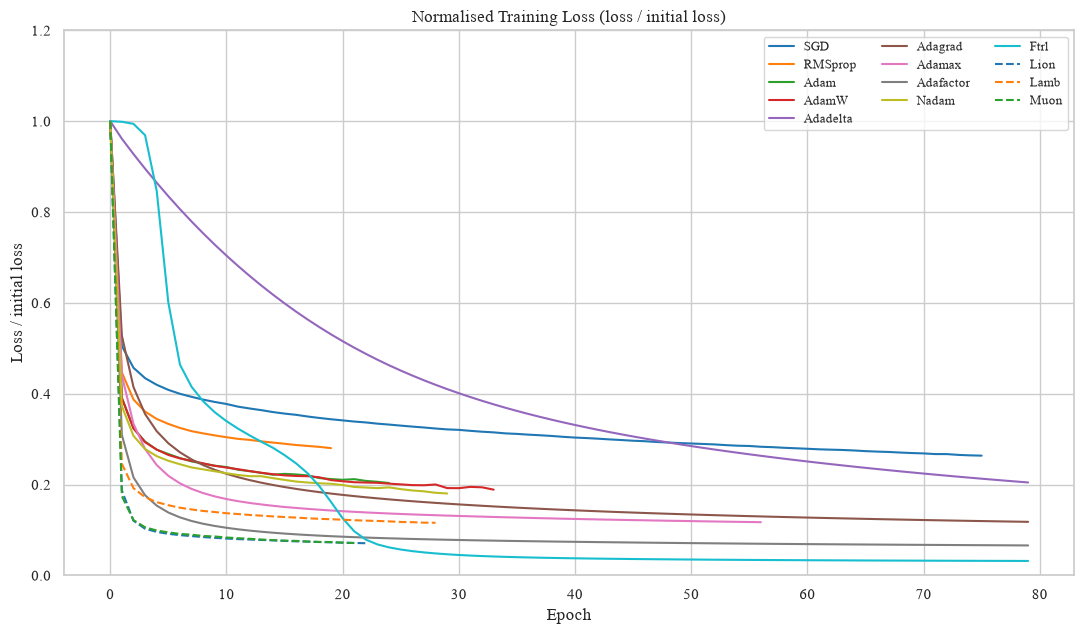

In [37]:
fig, ax = plt.subplots(figsize=(11, 6.5))
norm_curves = {}
for (name, h), col, ls in zip(histories.items(), palette, styles):
    tl = np.array(h['loss'])
    norm_curves[name] = tl / tl[0]
    ax.plot(np.arange(len(tl)), norm_curves[name], label=name, color=col, ls=ls)
ax.set_ylim(0, 1.2)
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss / initial loss')
ax.set_title('Normalised Training Loss (loss / initial loss)')
ax.legend(ncol=3, fontsize=9)
fig.tight_layout()
fig.savefig('fig_convergence_normalised.png', dpi=130, bbox_inches='tight')
plt.show()

In [38]:
rows = {}
for name, h in histories.items():
    tl = np.array(h['loss'])
    nc = tl / tl[0]
    steps = np.diff(tl) / tl[:-1]                               # relative change from one epoch to the next
    late = steps[5:] if len(steps) > 5 else steps               # ignore the steep first epochs when judging smoothness
    rows[name] = {
        'epoch-0 loss (original units)': tl[0] * SCALE2,
        'fraction removed by epoch 5 (%)': (1 - nc[5]) * 100,
        'normalised loss at epoch 5': nc[5],
        'epochs where train loss went UP': int((steps > 0).sum()),
        'largest upward jump (%)': float(max(0, steps.max() * 100)),
        'roughness (std of epoch-to-epoch % change, after epoch 5)': float(np.std(late) * 100),
    }
tbl_bonus = pd.DataFrame(rows).T.sort_values('fraction removed by epoch 5 (%)', ascending=False)
display(tbl_bonus.style.format({'epoch-0 loss (original units)': '{:.2e}', 'fraction removed by epoch 5 (%)': '{:.1f}',
                                'normalised loss at epoch 5': '{:.3f}', 'epochs where train loss went UP': '{:.0f}',
                                'largest upward jump (%)': '{:.2f}',
                                'roughness (std of epoch-to-epoch % change, after epoch 5)': '{:.3f}'}))

,epoch-0 loss (original units),fraction removed by epoch 5 (%),normalised loss at epoch 5,epochs where train loss went UP,largest upward jump (%),"roughness (std of epoch-to-epoch % change, after epoch 5)"
Lion,7.90e+08,90.9,0.091,0,0.00,0.659
Muon,7.26e+08,90.5,0.095,0,0.00,0.805
Adafactor,9.13e+08,86.2,0.138,0,0.00,1.398
Lamb,4.97e+08,84.6,0.154,0,0.00,0.741
Adamax,4.94e+08,78.1,0.219,0,0.00,1.490
Nadam,3.01e+08,74.8,0.252,1,0.86,0.838
AdamW,2.84e+08,73.5,0.265,2,1.47,1.136
Adam,2.84e+08,73.3,0.267,2,0.88,1.043
Adagrad,1.06e+09,70.9,0.291,0,0.00,1.267
RMSprop,2.30e+08,66.7,0.333,0,0.00,0.552


## Bonus Question — Normalised Convergence
**(a)** Normalizing by the initial loss removes the absolute scale. What does this allow you to compare fairly across optimizers?

**(b)** Identify the optimizer that reduced its normalised loss by the greatest fraction within the first 5 epochs. Explain why this specific optimizer converges so rapidly in the early phase.

**(c)** Which optimizer maintained the most stable convergence (smoothest curve without large oscillations)? Why might stability matter more than raw speed in a production setting?

### Answer
**(a)** Dividing each training-loss curve by its epoch-0 loss makes all curves start at 1.0. This makes it easier to compare how quickly each optimizer reduces its own starting loss. The limitation is that a lower normalized loss does not necessarily mean a lower final loss, so the test RMSE table is still needed.

**(b)** Lion reduced its normalized loss the most by epoch 5: **90.9%**. Muon was next at **90.5%**, followed by Adafactor at 86.2% and Lamb at 84.6%. Adadelta removed only 16.5%. Fast early loss reduction did not always mean the best final result, although Lion also achieved the best test RMSE.

**(c)** SGD had the lowest roughness score at **0.369**, followed by RMSprop at 0.552. Ftrl had the highest score at 5.586, but its training loss did not rise; its large score reflects its steep changes. Stability matters more than raw speed in production because a stable optimizer gives nearly the same model every time it is retrained on new survey data, and early stopping can pick the best epoch reliably. A fast but jumpy run can stop at a poor epoch and needs extra monitoring.